# Pruebas_COG_LOLA
## Prototipo de evaluación topográfica, iluminación y visibilidad terrestre lunar

Python · LOLA / SLDEM2015 · HTTP Range · JPL Horizons. Preparado el **14-11-2026**.

Este cuaderno implementa los experimentos solicitados sin crear API ni frontend. El índice es
experimental: **no es una probabilidad de aterrizaje seguro**. Las pruebas sintéticas verifican
fórmulas y están separadas de los experimentos con datos NASA; una fuente inaccesible produce un
resultado incompleto, nunca un DEM sintético de sustitución.

**Uso:** instala `Pruebas_COG_LOLA/requirements.txt`, selecciona ese kernel y ejecuta de arriba abajo.
La ejecución normal hace pruebas pequeñas con datos reales. El horizonte completo y las series largas
se activan en la configuración porque pueden requerir muchas lecturas remotas. Las funciones están
en el propio notebook y pueden extraerse a módulos Python.

### 1. Parámetros editables

Latitud planetocéntrica, longitud positiva al este, marco **MOON_ME / DE421**, distancias y alturas
en metros; UTC para tiempos. No se utiliza EPSG:4326, que corresponde a la Tierra.
Azimut: 0° norte, 90° este, 180° sur, 270° oeste; elevación respecto al plano tangente radial.
La Luna se aproxima por una esfera de radio $R=1\,737\,400$ m.

Se conservan las coordenadas y el instante del enunciado para Apolo 11 como caso reproducible.
[NASA NSSDCA](https://nssdc.gsfc.nasa.gov/planetary/lunar/apollo11info.html) confirma
20-07-1969 20:17:40 UT y coordenadas redondeadas 0,67° N, 23,47° E.
[LROC](https://www.lroc.im-ldi.com/featured_sites/apollo-11/temporal-traverse) publica
0,67416° N, 23,47314° E. El [resumen histórico de NASA](https://www.nasa.gov/wp-content/uploads/static/history/SP-4029/Apollo_11a_Summary.htm)
da 20:17:39 GMT y 0,67408° N, 23,47297° E: hay diferencias de redondeo/cronología.
No se afirma una exactitud de un segundo ni una transformación entre datums históricos.
Las coordenadas redondeadas de entrada se interpretan aquí en ME/DE421 para consultar el DEM;
esto no demuestra por sí solo la posición histórica exacta en ese marco.

In [12]:
LATITUDE = 0.674
LONGITUDE = 23.473
UTC_TIME = "1969-07-20T20:17:40Z"
ANALYSIS_RADIUS_M = 1500.0
MINIMUM_OBSTACLE_SIZE_M = 100.0
PIXELS_PER_OBSTACLE = 5
EPHEMERIS_MODE = "manual"           # "manual" o "horizons"
SOLAR_AZIMUTH_DEG, SOLAR_ELEVATION_DEG = 90.0, 10.0  # ejemplos, NO efemérides de Apolo 11
EARTH_AZIMUTH_DEG, EARTH_ELEVATION_DEG = 260.0, 60.0
SOLAR_DIAMETER_DEG = None            # None: sólo visibilidad del centro
OBSERVER_HEIGHT_M = 2.0
MAX_SLOPE_DEG = 12.0                 # umbrales de experimento, no oficiales
MAX_ROUGHNESS_M = 3.0
MAX_RELIEF_M = 100.0
HORIZON_TOLERANCE_DEG = 0.05
AZIMUTH_STEP_DEG = 10.0              # 0.5 produce 720 direcciones
RESOLUTION_STRATEGY = [(0.0, 5000.0, 5.0),
                       (5000.0, 100000.0, 80.0),
                       (100000.0, float("inf"), 240.0)]
MAX_TERRAIN_HEIGHT_M = 20000.0       # envolvente asumida, no máximo oficial certificado
RUN_REMOTE_EXPERIMENTS = True
RUN_HORIZONS_CHECK = True           # consulta corta, independiente del modo manual
RUN_LOCAL_PROFILE_DEMO = True       # perfil de sólo 5 km, explícitamente truncado
RUN_DIRECTIONAL_HORIZON = False
RUN_FULL_HORIZON = False
RUN_TIME_SERIES = False
RUN_REMOTE_SENSITIVITY = False
TIME_START = "1969-07-20T20:17:40Z"
TIME_END = "1969-07-21T20:17:40Z"
TIME_STEP = "1 h"
MAX_OUTPUT_PIXELS = 2_000_000
MAX_SOURCE_WINDOW_PIXELS = 4_000_000
CACHE_MEMORY_MB = 128
MAX_RANGE_REQUEST_BYTES = 2 * 1024 * 1024

### 2. Dependencias, registro y control del acceso remoto

In [13]:
from __future__ import annotations
from dataclasses import dataclass
from functools import lru_cache
from collections import OrderedDict
from contextlib import contextmanager
from datetime import datetime, timedelta, timezone
from html.parser import HTMLParser
from pathlib import Path
from time import perf_counter
from typing import Any, Iterator, Sequence
from urllib.parse import urljoin, urlparse
import csv, io, json, math, re, warnings, tracemalloc
import numpy as np
import requests
import rasterio
from rasterio.windows import Window, from_bounds
from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling
from rasterio.io import MemoryFile
from pyproj import CRS, Transformer, Geod, Proj
from scipy import ndimage
from scipy.optimize import brentq
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

R_MOON = 1_737_400.0
LUNAR_CRS = CRS.from_proj4(f"+proj=longlat +R={R_MOON} +no_defs +type=crs")
GEOD = Geod(a=R_MOON, b=R_MOON)
SESSION = requests.Session()
SESSION.headers['User-Agent'] = 'Pruebas-COG-LOLA/1.0 research-notebook'
SESSION.headers['Accept-Encoding'] = 'identity'
HTTP_LOG: list[dict[str, Any]] = []
PERFORMANCE: list[dict[str, Any]] = []
PROBLEMS: list[str] = []
REMOTE_RESULTS: dict[str, Any] = {}
SOURCE_AUDIT: dict[str, dict[str, Any]] = {}

@contextmanager
def measure(name: str) -> Iterator[dict[str, Any]]:
    """Registra tiempo y pico Python; no equivale a RSS ni a memoria nativa GDAL."""
    own_trace = not tracemalloc.is_tracing()
    if own_trace: tracemalloc.start()
    start = perf_counter()
    record = {'experiment': name}
    try:
        yield record
    finally:
        record['seconds'] = perf_counter() - start
        record['python_peak_bytes'] = tracemalloc.get_traced_memory()[1]
        if own_trace: tracemalloc.stop()
        PERFORMANCE.append(record)

def small_get(url: str, limit: int = 1_000_000,
              params: dict[str, str] | None = None) -> str:
    """Lee sólo documentos pequeños con límite explícito; registra bytes de aplicación."""
    with SESSION.get(url, params=params, stream=True, timeout=(10, 45)) as response:
        response.raise_for_status()
        data = response.raw.read(limit + 1)
        HTTP_LOG.append({'url': response.url, 'status': response.status_code,
                         'body_bytes': len(data), 'kind': 'document'})
        if len(data) > limit: raise ValueError('Documento excede el límite')
        return data.decode('utf-8', errors='replace')

def read_http_range(url: str, first: int, last: int) -> tuple[bytes, int]:
    """Exige HTTP 206 y Content-Range exacto; cierra un HTTP 200 sin consumir su cuerpo."""
    if not 0 <= first <= last or last-first+1 > MAX_RANGE_REQUEST_BYTES:
        raise ValueError('Rango inválido o demasiado grande')
    with SESSION.get(url, headers={'Range': f'bytes={first}-{last}',
                                  'Accept-Encoding': 'identity'}, stream=True,
                     timeout=(10, 45)) as response:
        content_range = response.headers.get('Content-Range', '')
        m = re.fullmatch(r'bytes (\d+)-(\d+)/(\d+)', content_range)
        if response.status_code != 206 or not m:
            raise RuntimeError(f'Sin acceso parcial: HTTP {response.status_code}, {content_range}')
        begin, end, total = map(int, m.groups())
        if (begin, end) != (first, last): raise RuntimeError('Range distinto al solicitado')
        data = response.raw.read(last-first+2)
        if len(data) != last-first+1: raise RuntimeError('Respuesta parcial truncada o excesiva')
        HTTP_LOG.append({'url': url, 'status': 206, 'first': first, 'last': last,
                         'total_file_bytes': total, 'body_bytes': len(data), 'kind': 'range'})
        return data, total

GDAL_OPTIONS = dict(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR',
                    CPL_VSIL_CURL_ALLOWED_EXTENSIONS='.TIF,.tif,.IMG,.LBL',
                    GDAL_HTTP_TIMEOUT='45', GDAL_HTTP_MAX_RETRY='2', GDAL_HTTP_RETRY_DELAY='1',
                    CPL_VSIL_CURL_CHUNK_SIZE='16384', GDAL_CACHEMAX=64,
                    VSI_CACHE=True, VSI_CACHE_SIZE=16*1024*1024)
print('Rasterio', rasterio.__version__, 'GDAL', rasterio.__gdal_version__)

Rasterio 1.5.2 GDAL 3.12.2


### 3. Catálogo verificable y metadatos

Los enlaces de archivo se **descubren en los índices oficiales**; no se construyen URLs de datos
inexistentes. Se audita cada candidato antes de usarlo.

| Fuente | Productos y cobertura documentada | Acceso |
|---|---|---|
| [PGDA 90](https://pgda.gsfc.nasa.gov/products/90) | DEM, pendiente, errores, resolución efectiva; casquetes 60–90°, 75–90°, 80–90° y 83–90° S según archivo; rugosidad a distintas bases | COG publicados, comprobar `LAYOUT`, bloques, overviews y HTTP 206 |
| [PGDA 78](https://pgda.gsfc.nasa.gov/products/78) | Sitios polares de 5 m: altura, error RMS, pendiente y conteos | GeoTIFF; **no presupone COG**. Shackleton verificado como tiras sin overviews |
| [Imbrium](https://imbrium.mit.edu/) / [SLDEM2015 tiles](https://imbrium.mit.edu/DATA/SLDEM2015/TILES/FLOAT_IMG/) | Elevación LOLA + Kaguya, ±60°, 512 ppd (~59 m en ecuador) | PDS IMG + LBL, alternativa Range; no COG |
| [PGDA 67](https://pgda.gsfc.nasa.gov/products/67) | Pendiente y azimut derivados, 64–512 ppd; escala de medida distinta en cada versión | IMG / JP2, no proporciona por sí solo un DEM COG |
| [PDS Geosciences](https://pds-geosciences.wustl.edu/missions/lro/lola.htm) | Catálogo y documentación de LOLA | Portal de referencia |

El tamaño de píxel no es la resolución efectiva. Se consulta `EFFRES` cuando existe; sin ese mapa
se usa el tamaño de píxel sólo como límite optimista y se declara la incertidumbre. Las unidades
de los TIF del PGDA se documentan en la página, aunque la banda no tenga `units`.
SLDEM2015 contiene **alturas en km** respecto a 1737,4 km: se multiplican los DN por 1000,
sin sumar el `OFFSET` radial que GDAL muestra en la etiqueta PDS. La [etiqueta del tile de Apolo 11](https://imbrium.mit.edu/DATA/SLDEM2015/TILES/FLOAT_IMG/SLDEM2015_512_00N_30N_000_045_FLOAT.LBL)
es la autoridad para esta conversión, el marco ME/DE421 y el registro de píxeles.

In [14]:
SOURCES = {
    'pgda90': 'https://pgda.gsfc.nasa.gov/products/90',
    'pgda78': 'https://pgda.gsfc.nasa.gov/products/78',
    'pgda67': 'https://pgda.gsfc.nasa.gov/products/67',
    'pds': 'https://pds-geosciences.wustl.edu/missions/lro/lola.htm',
    'sldem': 'https://imbrium.mit.edu/DATA/SLDEM2015/TILES/FLOAT_IMG/',
}

class LinkParser(HTMLParser):
    """Extrae href sin depender de bibliotecas HTML adicionales."""
    def __init__(self) -> None:
        super().__init__(); self.links: list[str] = []
    def handle_starttag(self, tag: str, attrs: list[tuple[str, str | None]]) -> None:
        if tag == 'a':
            self.links.extend(v for k, v in attrs if k == 'href' and v)

@lru_cache(maxsize=16)
def official_links(page: str) -> tuple[str, ...]:
    """Obtiene enlaces reales y conserva únicamente dominios de las fuentes conocidas."""
    p = LinkParser(); p.feed(small_get(page))
    hosts = {'pgda.gsfc.nasa.gov', 'imbrium.mit.edu', 'pds-geosciences.wustl.edu'}
    return tuple(dict.fromkeys(urljoin(page, x) for x in p.links
        if urlparse(urljoin(page, x)).hostname in hosts))

@dataclass(frozen=True)
class Dataset:
    """Descripción documental mínima; las propiedades ráster se verifican al abrir."""
    name: str
    url: str
    source: str
    nominal_m: float
    south: float
    north: float
    west: float = 0.0
    east: float = 360.0
    elevation_scale: float = 1.0
    effective_url: str | None = None
    error_url: str | None = None
    slope_url: str | None = None
    is_pds: bool = False

@lru_cache(maxsize=1)
def build_catalog() -> tuple[Dataset, ...]:
    """Descubre DEM del producto 90, Site04 y tiles SLDEM2015 de 512 ppd."""
    result: list[Dataset] = []
    for key in ('pgda90', 'pgda78', 'sldem'):
        try: links = official_links(SOURCES[key])
        except Exception as exc:
            PROBLEMS.append(f'{key}: {exc}'); continue
        names = {urlparse(u).path.rsplit('/', 1)[-1]: u for u in links}
        if key == 'pgda90':
            for name, url in names.items():
                m = re.fullmatch(r'LDEM_(\d+)S_(\d+)MPP_ADJ\.TIF', name)
                if m:
                    lat, resolution = map(int, m.groups())
                    result.append(Dataset(name, url, SOURCES[key], resolution, -90., -float(lat),
                        effective_url=names.get(name.replace('.TIF', '_EFFRES.TIF')),
                        error_url=names.get(name.replace('.TIF', '_ERR.TIF')),
                        slope_url=names.get(name.replace('LDEM', 'LDSM'))))
        elif key == 'pgda78':
            name = 'Site04_final_adj_5mpp_surf.tif'
            if name in names:
                result.append(Dataset(name, names[name], SOURCES[key], 5., -90., -89.,
                    error_url=names.get(name.replace('_surf', '_toterr')),
                    slope_url=names.get(name.replace('_surf', '_slp'))))
        else:
            pattern = r'SLDEM2015_512_(\d+)([NS])_(\d+)([NS])_(\d+)_(\d+)_FLOAT\.LBL'
            for name, url in names.items():
                m = re.fullmatch(pattern, name)
                if m:
                    a, sa, b, sb, west, east = m.groups()
                    lat1 = float(a)*(1 if sa == 'N' else -1)
                    lat2 = float(b)*(1 if sb == 'N' else -1)
                    result.append(Dataset(name, url, SOURCES[key], np.pi*R_MOON/180/512,
                        min(lat1, lat2), max(lat1, lat2), float(west), float(east), 1000., is_pds=True))
    if not result: raise RuntimeError('No se pudo descubrir ningún dataset oficial')
    return tuple(result)

def get_available_datasets(latitude: float, longitude: float) -> list[Dataset]:
    """Candidatos por cobertura documental; la ventana real/NoData se comprueba después."""
    if not -90 <= latitude <= 90 or not np.isfinite(longitude):
        raise ValueError('Coordenadas lunares inválidas')
    lon = longitude % 360
    return [d for d in build_catalog() if d.south <= latitude <= d.north
            and d.west <= lon < d.east]

@lru_cache(maxsize=100)
def dataset_metadata(url: str, is_pds: bool = False) -> dict[str, Any]:
    """Audita transporte, CRS, tamaño de píxel, cobertura y organización del archivo."""
    data_url = url
    label = None
    if is_pds:
        label = small_get(url, limit=100_000)
        m = re.search(r'\^IMAGE\s*=\s*"([^"]+)"', label)
        if not m: raise ValueError('Etiqueta PDS sin ^IMAGE simple')
        data_url = urljoin(url, m.group(1))
        # Valida explícitamente el contrato soportado; no interpreta productos PDS arbitrarios.
        for token in ('PC_REAL', 'KILOMETER', 'MEAN EARTH/POLAR AXIS OF DE421'):
            if token not in label: raise ValueError(f'Etiqueta PDS inesperada: falta {token}')
    _, total = read_http_range(data_url, 0, 1023)
    with rasterio.Env(**GDAL_OPTIONS), rasterio.open('/vsicurl/' + url) as src:
        crs = CRS.from_user_input(src.crs)
        if not math.isclose(crs.ellipsoid.semi_major_metre, R_MOON, abs_tol=1.):
            raise ValueError('Radio del CRS incompatible con el modelo lunar')
        to_geo=Transformer.from_crs(crs,LUNAR_CRS,always_xy=True)
        bx=np.linspace(src.bounds.left,src.bounds.right,65)
        by=np.linspace(src.bounds.bottom,src.bounds.top,65)
        gx,gy=np.meshgrid(bx,by)
        _,glat=to_geo.transform(gx,gy)
        meta = dict(url=url, data_url=data_url, total_file_bytes=total,
            crs_wkt=src.crs.to_wkt(), projection=crs.coordinate_operation.method_name,
            resolution=src.res, bounds=tuple(src.bounds), shape=src.shape,
            transform=src.transform, nodata=src.nodata, overviews=src.overviews(1),
            blocks=src.block_shapes, tiled=src.profile.get('tiled', False),
            image_structure=src.tags(ns='IMAGE_STRUCTURE'), scale=src.scales[0],
            offset=src.offsets[0], units=src.units[0], tags=src.tags(),
            frame='MOON_ME/DE421 (documentación)', vertical_reference_m=R_MOON,
            longitude='este positivo, 0–360', label=label,
            rectangular_grid_latitude_range_deg=(float(np.min(glat)),float(np.max(glat))))
        meta['cog_layout_reported'] = meta['image_structure'].get('LAYOUT') == 'COG'
        # LAYOUT es una comprobación práctica; no sustituye una validación exhaustiva OGC COG.
        SOURCE_AUDIT[url] = meta
        return meta

def source_xy(dataset: Dataset, latitude: Any, longitude: Any) -> tuple[Any, Any]:
    """Proyecta coordenadas esféricas lunares en el CRS nativo usando siempre lon, lat."""
    meta = dataset_metadata(dataset.url, dataset.is_pds)
    t = lunar_transformer(meta['crs_wkt'])
    return t.transform(longitude, latitude)

@lru_cache(maxsize=32)
def lunar_transformer(target_wkt: str) -> Transformer:
    """Reutiliza transformaciones de coordenadas para perfiles con muchos puntos."""
    return Transformer.from_crs(LUNAR_CRS,CRS.from_wkt(target_wkt),always_xy=True)

def select_dataset(latitude: float, longitude: float, target_resolution: float) -> Dataset:
    """Elige el píxel más grueso que cumpla el objetivo, o el más fino accesible.

    La selección nominal no certifica resolución efectiva; ésta se mide en la ventana.
    """
    if target_resolution <= 0: raise ValueError('Resolución debe ser positiva')
    candidates = get_available_datasets(latitude, longitude)
    fine = sorted((d for d in candidates if d.nominal_m <= target_resolution),
                  key=lambda d: d.nominal_m, reverse=True)
    coarse = sorted((d for d in candidates if d.nominal_m > target_resolution),
                    key=lambda d: d.nominal_m)
    for d in fine + coarse:
        try:
            meta = dataset_metadata(d.url, d.is_pds)
            x, y = source_xy(d, latitude, longitude)
            left, bottom, right, top = meta['bounds']
            if left <= x < right and bottom < y <= top:
                return d
        except Exception as exc:
            PROBLEMS.append(f'{d.name}: {exc}')
    raise RuntimeError(f'Sin DEM accesible para ({latitude}, {longitude})')

### 4. Ventanas, caché y rejilla métrica local

La resolución objetivo es $r_t=L_{min}/n$: tamaño mínimo de obstáculo dividido por el
número de píxeles requerido (5 por defecto). Se compara con el píxel físico y con EFFRES
cuando existe. Si cualquiera es más grueso, el obstáculo solicitado no queda resuelto.

Para comparar pendientes se reproyecta una **ventana pequeña** a una proyección azimutal
equidistante centrada en el sitio. Así $dx,dy$ están en metros y se evita aplicar diferencias
en grados o ignorar la distorsión de una proyección cilíndrica a latitudes altas.
Se usa vecino más cercano; el paso de salida nunca es menor que el paso físico nativo más
grueso. Reproyectar no añade información ni resuelve obstáculos subpíxel.

La caché LRU guarda ventanas, con un límite de memoria, y GDAL reutiliza bloques HTTP.
Para IMG se abre la etiqueta LBL con el driver PDS de Rasterio: es una lectura por ventanas,
no una descarga del tile completo. Las esquinas y los límites entre tiles se conservan como
NoData si una ventana rebasa la cobertura; no se rellenan huecos por interpolación.

In [15]:
WINDOW_CACHE: OrderedDict[tuple, np.ndarray] = OrderedDict()
CACHE_BYTES = 0

def read_window(url: str, window: Window, scale: float = 1.) -> np.ndarray:
    """Lee una ventana nativa con Rasterio, aplica escala documental y conserva NoData."""
    global CACHE_BYTES
    w = Window(int(window.col_off), int(window.row_off), int(window.width), int(window.height))
    if w.width*w.height > MAX_SOURCE_WINDOW_PIXELS:
        raise ValueError('Ventana fuente excesiva: reduzca radio o elija un producto más grueso')
    key = (url, tuple(w.flatten()), scale)
    if key in WINDOW_CACHE:
        WINDOW_CACHE.move_to_end(key); return WINDOW_CACHE[key]
    for attempt in range(2):
        try:
            with rasterio.Env(**GDAL_OPTIONS), rasterio.open('/vsicurl/'+url) as src:
                arr = src.read(1, window=w, masked=True).astype('float64').filled(np.nan) * scale
            break
        except rasterio.errors.RasterioError:
            if attempt == 1: raise
    limit = CACHE_MEMORY_MB*1024**2
    if arr.nbytes <= limit:
        while WINDOW_CACHE and CACHE_BYTES + arr.nbytes > limit:
            _, old = WINDOW_CACHE.popitem(last=False); CACHE_BYTES -= old.nbytes
        WINDOW_CACHE[key] = arr; CACHE_BYTES += arr.nbytes
    return arr

@dataclass
class DEMWindow:
    """DEM métrico local y evidencias de escala/cobertura."""
    elevation: np.ndarray
    dx: float
    dy: float
    transform: Any
    crs: CRS
    dataset: Dataset
    effective_resolution_m: float | None
    vertical_rms_m: float | None
    coverage_fraction: float
    target_resolution_m: float
    warnings: list[str]

def native_ground_spacing(d: Dataset, lat: float) -> float:
    """Paso físico aproximado más grueso considerando factores cartográficos locales."""
    meta = dataset_metadata(d.url, d.is_pds)
    factors = Proj(CRS.from_wkt(meta['crs_wkt'])).get_factors(0 if not d.is_pds else 180, lat)
    return max(meta['resolution'][0]/factors.parallel_scale,
               meta['resolution'][1]/factors.meridional_scale)

def get_dem(latitude: float, longitude: float, radius_m: float,
            resolution_m: float) -> DEMWindow:
    """Obtiene una ventana circular real en AEQD local; no simula resolución superior."""
    if radius_m <= 0: raise ValueError('Radio debe ser positivo')
    start = perf_counter()
    d = select_dataset(latitude, longitude, resolution_m)
    meta = dataset_metadata(d.url, d.is_pds)
    spacing = max(resolution_m, native_ground_spacing(d, latitude))
    n = 2*int(np.ceil(radius_m/spacing))+1
    if n*n > MAX_OUTPUT_PIXELS: raise ValueError('Demasiados píxeles de salida')
    local = CRS.from_proj4(f'+proj=aeqd +lat_0={latitude} +lon_0={longitude} +R={R_MOON} +units=m')
    dst_transform = from_origin(-n*spacing/2, n*spacing/2, spacing, spacing)
    native = CRS.from_wkt(meta['crs_wkt'])
    t = Transformer.from_crs(local, native, always_xy=True)
    edge = n*spacing/2
    a = np.linspace(-edge, edge, 33)
    ex = np.concatenate([a, a, np.full(33,-edge), np.full(33,edge)])
    ey = np.concatenate([np.full(33,-edge), np.full(33,edge), a, a])
    xs, ys = t.transform(ex, ey)
    wf = from_bounds(min(xs), min(ys), max(xs), max(ys), transform=meta['transform'])
    c0, r0 = max(0, int(np.floor(wf.col_off))-2), max(0, int(np.floor(wf.row_off))-2)
    c1 = min(meta['shape'][1], int(np.ceil(wf.col_off+wf.width))+2)
    r1 = min(meta['shape'][0], int(np.ceil(wf.row_off+wf.height))+2)
    if c1 <= c0 or r1 <= r0: raise ValueError('Ventana fuera de cobertura')
    window = Window(c0, r0, c1-c0, r1-r0)
    src_transform = rasterio.windows.transform(window, meta['transform'])
    circle_y, circle_x = np.mgrid[:n,:n]
    disk = ((circle_x-(n-1)/2)*spacing)**2+((circle_y-(n-1)/2)*spacing)**2 <= radius_m**2

    def local_band(url: str, scale: float = 1.) -> np.ndarray:
        """Reproyecta una ventana coincidente a la rejilla local sin suavizar picos."""
        source = read_window(url, window, scale)
        dest = np.full((n,n), np.nan)
        reproject(source, dest, src_transform=src_transform, src_crs=native,
                  dst_transform=dst_transform, dst_crs=local, src_nodata=np.nan,
                  dst_nodata=np.nan, resampling=Resampling.nearest)
        dest[~disk] = np.nan
        return dest

    z = local_band(d.url, d.elevation_scale)
    notes = []
    quality = {}
    for label, url in [('effective', d.effective_url), ('error', d.error_url)]:
        quality[label] = None
        if url:
            try:
                # Verifica Range antes de permitir que GDAL abra una banda auxiliar.
                dataset_metadata(url)
                band = local_band(url)
                valid = band[np.isfinite(band) & (band >= 0)]
                quality[label] = float(np.percentile(valid, 95)) if valid.size else None
            except Exception as exc: notes.append(f'{label} no disponible: {exc}')
    effective = quality['effective']
    if effective is None: notes.append('Resolución efectiva desconocida; píxel es límite optimista')
    if max(spacing, effective or spacing) > resolution_m*(1+1e-6):
        notes.append(f'Resolución insuficiente: objetivo {resolution_m:.2f} m; '
                     f'paso {spacing:.2f} m; efectiva P95 {effective}')
    coverage = float(np.count_nonzero(np.isfinite(z) & disk)/np.count_nonzero(disk))
    if coverage < 0.999: notes.append('Cobertura parcial: no se han rellenado huecos ni bordes de tiles')
    if not np.isfinite(z).any(): raise ValueError('Ventana sin elevaciones válidas')
    result = DEMWindow(z, spacing, spacing, dst_transform, local, d,
                       effective, quality['error'], coverage, resolution_m, notes)
    PERFORMANCE.append(dict(experiment='get_dem', seconds=perf_counter()-start,
        shape=z.shape, matrix_bytes=z.nbytes, source_pixels=int(window.width*window.height),
        output_resolution_m=spacing, effective_resolution_p95_m=effective,
        gdal_http_requests=None, gdal_transfer_bytes=None))
    return result

def get_elevation(latitude: float, longitude: float) -> float:
    """Altura en m del píxel más fino accesible; no certifica precisión subpíxel."""
    d = select_dataset(latitude, longitude, 5.)
    meta = dataset_metadata(d.url, d.is_pds)
    x, y = source_xy(d, latitude, longitude)
    row, col = rasterio.transform.rowcol(meta['transform'], x, y)
    value = float(read_window(d.url, Window(col, row, 1, 1), d.elevation_scale)[0,0])
    if not np.isfinite(value): raise ValueError('NoData en el punto de observación')
    return value

### 5. Pendiente, plano residual y curvatura

Con $p=\partial z/\partial x$ y $q=\partial z/\partial y$, la pendiente es
$s=\arctan\sqrt{p^2+q^2}$ (grados). El plano se ajusta por mínimos cuadrados:
$\hat\beta=\arg\min_\beta\|A\beta-z\|^2$, $A_i=(x_i,y_i,1)$.
Los residuos $r_i=z_i-(ax_i+by_i+c)$ definen $RMS=\sqrt{\langle r_i^2\rangle}$,
$\max|r_i|$ y percentiles. El desnivel es $\max z-\min z$ y la pendiente del plano
$\arctan\sqrt{a^2+b^2}$. Son medidas dependientes del radio y del soporte espacial.

La Hessiana es $H=\begin{pmatrix}z_{xx}&z_{xy}\\z_{xy}&z_{yy}\end{pmatrix}$,
su traza es el laplaciano. Dos autovalores positivos indican forma de cuenco (convexidad
matemática de la función de altura, depresión topográfica); dos negativos indican cúpula;
signos opuestos, silla. No se identifican cráteres confirmados con este criterio.
Se enmascaran los vecindarios de NoData; no se sustituyen por cero.

In [16]:
def _terrain_inputs(dem: np.ndarray, dx: float, dy: float) -> np.ndarray:
    """Valida rejilla métrica bidimensional para diferencias finitas."""
    z = np.asarray(dem, dtype=float)
    if z.ndim != 2 or min(z.shape) < 3 or min(dx,dy) <= 0:
        raise ValueError('DEM 2D de al menos 3x3 y pasos positivos requeridos')
    return z

def calculate_slope(dem: np.ndarray, dx: float, dy: float) -> np.ndarray:
    """Ángulo de pendiente (°) con diferencias finitas; bordes/NoData excluidos."""
    z = _terrain_inputs(dem, dx, dy)
    zy, zx = np.gradient(z, dy, dx, edge_order=2)
    slope = np.degrees(np.arctan(np.hypot(zx,zy)))
    valid = ndimage.binary_erosion(np.isfinite(z), iterations=1, border_value=0)
    return np.where(valid, slope, np.nan)

def slope_statistics(slope: np.ndarray, limit_deg: float) -> dict[str, float]:
    """Estadísticos sólo sobre pendientes calculables; informa soporte válido."""
    values = slope[np.isfinite(slope)]
    if not values.size: raise ValueError('Sin soporte para pendiente')
    center = tuple(s//2 for s in slope.shape)
    return dict(center_deg=float(slope[center]), mean_deg=float(np.mean(values)),
        max_deg=float(np.max(values)), p95_deg=float(np.percentile(values,95)),
        area_above_limit_pct=float(100*np.mean(values>limit_deg)),
        valid_pixels=int(values.size))

def calculate_roughness(dem: np.ndarray, dx: float, dy: float) -> dict[str, Any]:
    """Ajusta plano a píxeles válidos y devuelve residuos y métricas en metros."""
    z = _terrain_inputs(dem, dx, dy)
    row, col = np.indices(z.shape)
    x = (col-(z.shape[1]-1)/2)*dx
    y = ((z.shape[0]-1)/2-row)*dy
    valid = np.isfinite(z)
    a = np.column_stack([x[valid], y[valid], np.ones(valid.sum())])
    if valid.sum()<3 or np.linalg.matrix_rank(a)<3: raise ValueError('Plano no identificable')
    beta, *_ = np.linalg.lstsq(a, z[valid], rcond=None)
    fitted = beta[0]*x + beta[1]*y + beta[2]
    residual = np.where(valid, z-fitted, np.nan)
    v = residual[valid]
    return dict(rms_m=float(np.sqrt(np.mean(v*v))), max_absolute_m=float(np.max(np.abs(v))),
        relief_m=float(np.ptp(z[valid])), percentiles_m=dict(zip([5,25,50,75,95],
        map(float,np.percentile(v,[5,25,50,75,95])))),
        plane_slope_deg=float(np.degrees(np.arctan(np.hypot(*beta[:2])))),
        coefficients=beta, fitted=fitted, residual=residual, x=x, y=y)

def calculate_curvature(dem: np.ndarray, dx: float, dy: float) -> dict[str, np.ndarray]:
    """Laplaciano y autovalores de H en m^-1; derivadas en rejilla x derecha/y filas."""
    z = _terrain_inputs(dem,dx,dy)
    zy,zx = np.gradient(z,dy,dx,edge_order=2)
    zyy,zyx = np.gradient(zy,dy,dx,edge_order=2)
    zxy,zxx = np.gradient(zx,dy,dx,edge_order=2)
    mixed = (zxy+zyx)/2
    trace = zxx+zyy
    discr = np.sqrt((zxx-zyy)**2+4*mixed**2)
    valid = ndimage.binary_erosion(np.isfinite(z),iterations=2,border_value=0)
    clean = lambda a: np.where(valid,a,np.nan)
    return dict(laplacian=clean(trace), hxx=clean(zxx), hyy=clean(zyy),
                hxy=clean(mixed), lambda_min=clean((trace-discr)/2),
                lambda_max=clean((trace+discr)/2))

def detect_potential_depressions(dem: np.ndarray, dx: float, dy: float,
                               threshold: float = 1e-6,
                               min_pixels: int = 4) -> dict[str, Any]:
    """Clasifica cuencos/cúpulas/sillas; umbral exploratorio y filtro de área."""
    h = calculate_curvature(dem,dx,dy)
    low,high = h['lambda_min'],h['lambda_max']
    mask = low > threshold
    labels,n = ndimage.label(mask)
    counts = np.bincount(labels.ravel())
    keep = counts>=min_pixels; keep[0] = False
    depression = keep[labels]
    return dict(depressions=depression, domes=high < -threshold,
        saddles=(low < -threshold)&(high > threshold), curvature=h,
        candidate_regions=int(np.sum(keep)))

def roughness_at_scales(dem: DEMWindow, radii_m: Sequence[float]) -> list[dict[str,float]]:
    """Evalúa ventanas circulares de distintos radios sin cambiar el DEM de base."""
    yy,xx = np.indices(dem.elevation.shape)
    rr = np.hypot((xx-(xx.shape[1]-1)/2)*dem.dx,(yy-(yy.shape[0]-1)/2)*dem.dy)
    records=[]
    for radius in radii_m:
        if radius < 2*max(dem.dx,dem.dy): continue
        z = np.where(rr<=radius,dem.elevation,np.nan)
        try:
            q = calculate_roughness(z,dem.dx,dem.dy)
            records.append(dict(radius_m=float(radius),rms_m=q['rms_m'],relief_m=q['relief_m']))
        except ValueError: pass
    return records

### 6. Geometría del horizonte y límite de búsqueda

En la aproximación local, para distancia sobre el arco $d$:
$\alpha_{plana}=\operatorname{atan2}(z(d)-z_0-h-d^2/(2R),d)$.
En 3D se transforma cada punto a
$\mathbf p=(R+z)(\cos\phi\cos\lambda,\cos\phi\sin\lambda,\sin\phi)$.
La base ENU tiene $\mathbf e=(-\sin\lambda,\cos\lambda,0)$,
$\mathbf n=(-\sin\phi\cos\lambda,-\sin\phi\sin\lambda,\cos\phi)$ y
$\mathbf u=(\cos\phi\cos\lambda,\cos\phi\sin\lambda,\sin\phi)$.
Para $\Delta\mathbf p=\mathbf p-\mathbf p_0$,
$\alpha=\operatorname{atan2}(\Delta\mathbf p\cdot\mathbf u,
\sqrt{(\Delta\mathbf p\cdot\mathbf e)^2+(\Delta\mathbf p\cdot\mathbf n)^2})$.

Para cerrar la búsqueda se supone una envolvente $z\le z_{max}$ configurable y se utiliza
$\alpha_{max}(d)=\operatorname{atan2}((R+z_{max})\cos(d/R)-r_0,
(R+z_{max})\sin(d/R))$. Es decreciente para $R+z_{max}>r_0$.
Se busca hasta donde cae por debajo de $\alpha_{ref}+\epsilon$.
$\alpha_{ref}$ es el horizonte de una esfera lisa de radio $R+z_0$.
**Este cierre es condicional**: si el horizonte topográfico observado está por debajo de
$\alpha_{ref}$, no basta ese límite; el código amplía la búsqueda hasta satisfacer la cota
con el máximo realmente observado. Una distancia manual más corta se informa como truncada.
La envolvente de +20 km es una hipótesis amplia del prototipo y debe revisarse si se añaden
otras referencias verticales; no es un máximo oficial certificado.

La sección 4 del [manuscrito de Barker et al.](https://ntrs.nasa.gov/api/citations/20205009660/downloads/Mike%20Barker_%20Paper_%20Improved%20Lola.pdf?attachment=true)
confirma: 5 m para <5 km, 80 m para 5–100 km, 240 m después, y 720 azimuts cada 0,5°.
Se adopta como configuración inicial, ajustada a productos disponibles.

In [17]:
def lunar_xyz(latitude: Any, longitude: Any, elevation_m: Any) -> np.ndarray:
    """Cartesianas selenocéntricas de coordenadas planetocéntricas (m)."""
    lat,lon = np.radians(latitude),np.radians(longitude)
    radius = R_MOON+np.asarray(elevation_m)
    return np.stack([radius*np.cos(lat)*np.cos(lon),
                     radius*np.cos(lat)*np.sin(lon),radius*np.sin(lat)],axis=-1)

def enu_basis(latitude: float, longitude: float) -> np.ndarray:
    """Filas E,N,U de la base ortonormal radial local."""
    p,l = np.radians([latitude,longitude])
    return np.array([[-np.sin(l),np.cos(l),0],
        [-np.sin(p)*np.cos(l),-np.sin(p)*np.sin(l),np.cos(p)],
        [np.cos(p)*np.cos(l),np.cos(p)*np.sin(l),np.sin(p)]])

def exact_elevation_angles(latitude: float, longitude: float, z0: float, height: float,
                           lats: np.ndarray, lons: np.ndarray, zs: np.ndarray) -> np.ndarray:
    """Elevación exacta ENU para puntos de relieve y observador elevados."""
    observer = lunar_xyz(latitude,longitude,z0+height)
    rel = lunar_xyz(lats,lons,zs)-observer
    enu = rel @ enu_basis(latitude,longitude).T
    return np.degrees(np.arctan2(enu[...,2],np.hypot(enu[...,0],enu[...,1])))

def approximate_elevation_angles(distances: np.ndarray, zs: np.ndarray,
                                  z0: float, height: float) -> np.ndarray:
    """Referencia plana con corrección cuadrática por curvatura; d es arco (m)."""
    d = np.asarray(distances,dtype=float)
    return np.degrees(np.arctan2(np.asarray(zs)-z0-height-d*d/(2*R_MOON),d))

def smooth_horizon(z0: float, height: float) -> float:
    """Depresión angular del horizonte de esfera lisa del radio local (°)."""
    if height < 0: raise ValueError('Altura del observador negativa')
    return -float(np.degrees(np.arccos((R_MOON+z0)/(R_MOON+z0+height))))

def upper_envelope_angle(distance: float, z0: float, height: float,
                         zmax: float = MAX_TERRAIN_HEIGHT_M) -> float:
    """Cota de elevación a una distancia usando una envolvente radial uniforme."""
    t = distance/R_MOON
    return float(np.degrees(np.arctan2((R_MOON+zmax)*np.cos(t)-(R_MOON+z0+height),
                                      (R_MOON+zmax)*np.sin(t))))

def search_limit_m(z0: float, height: float, tolerance_deg: float,
                   reference_angle: float | None = None) -> float:
    """Resuelve el cierre geométrico hasta πR, condicionado a la envolvente zmax."""
    if tolerance_deg <= 0: raise ValueError('Tolerancia positiva requerida')
    if z0+height >= MAX_TERRAIN_HEIGHT_M: raise ValueError('Observador fuera de la envolvente asumida')
    threshold = (smooth_horizon(z0,height) if reference_angle is None else reference_angle)+tolerance_deg
    return float(brentq(lambda d: upper_envelope_angle(d,z0,height)-threshold,1e-3,np.pi*R_MOON-1))

def _sample_dataset(d: Dataset, lats: np.ndarray, lons: np.ndarray) -> np.ndarray:
    """Muestrea agrupando por ventanas 256x256, no una petición por punto."""
    meta = dataset_metadata(d.url,d.is_pds)
    x,y = source_xy(d,lats,lons)
    rows,cols = rasterio.transform.rowcol(meta['transform'],x,y)
    rows,cols = np.asarray(rows),np.asarray(cols)
    result = np.full(len(lats),np.nan)
    valid = (rows>=0)&(rows<meta['shape'][0])&(cols>=0)&(cols<meta['shape'][1])
    groups: dict[tuple[int,int],list[int]] = {}
    for i in np.where(valid)[0]: groups.setdefault((int(rows[i]//256),int(cols[i]//256)),[]).append(i)
    for (br,bc),idx in groups.items():
        r,c = br*256,bc*256
        w = Window(c,r,min(256,meta['shape'][1]-c),min(256,meta['shape'][0]-r))
        tile = read_window(d.url,w,d.elevation_scale)
        idxa = np.array(idx)
        result[idxa] = tile[rows[idxa]-r,cols[idxa]-c]
    return result

def get_elevation_profile(latitude: float, longitude: float, azimuth: float,
                          distances: Sequence[float], target_resolution: float = 80.) -> dict[str,Any]:
    """Perfil geodésico con selección por cobertura y resolución; conserva huecos."""
    distance = np.asarray(distances,dtype=float)
    if distance.ndim!=1 or np.any(distance<=0): raise ValueError('Distancias positivas requeridas')
    lons,lats,_ = GEOD.fwd(np.full(distance.size,longitude),np.full(distance.size,latitude),
                          np.full(distance.size,azimuth),distance)
    zs = np.full(distance.size,np.nan)
    used = np.full(distance.size,np.nan)
    groups: dict[Dataset,list[int]] = {}
    # Agrupa primero por cobertura documental para evitar abrir repetidamente cada punto.
    local_selections: dict[tuple,Dataset|None] = {}
    for i,(lat,lon) in enumerate(zip(lats,lons)):
        names = tuple(d.name for d in get_available_datasets(float(lat),float(lon)))
        # Site04 tiene cobertura rectangular: su selección exige verificar cada subzona.
        key = (names, round(float(lat),2),round(float(lon),2))
        if key not in local_selections:
            try: local_selections[key] = select_dataset(float(lat),float(lon),target_resolution)
            except Exception: local_selections[key] = None
        d = local_selections[key]
        if d is not None: groups.setdefault(d,[]).append(i)
    for d,idx in groups.items():
        indices = np.asarray(idx)
        try:
            zs[indices] = _sample_dataset(d,lats[indices],lons[indices])
            used[indices] = np.array([native_ground_spacing(d,float(p)) for p in lats[indices]])
        except Exception as exc: PROBLEMS.append(f'Perfil {d.name}: {exc}')
    return dict(distances_m=distance,latitude=lats,longitude=lons,elevation_m=zs,
                actual_spacing_m=used,datasets=[d.name for d in groups])

def calculate_horizon_angle(latitude: float, longitude: float, azimuth: float,
                            observer_height: float,
                            resolution_strategy: Sequence[tuple[float,float,float]] = RESOLUTION_STRATEGY,
                            max_distance_m: float | None = None,
                            tolerance_deg: float = HORIZON_TOLERANCE_DEG) -> dict[str,Any]:
    """Horizonte 3D muestreado, obstáculo dominante y cierre condicionado de distancia.

    No garantiza capturar máximos entre rayos/píxeles ni picos borrados en DEM promediados.
    """
    z0 = get_elevation(latitude,longitude)
    strategy = sorted(resolution_strategy)
    if not strategy or strategy[0][0] != 0 or not np.isinf(strategy[-1][1]):
        raise ValueError('Estrategia debe cubrir [0, infinito)')
    for i,(lo,hi,step) in enumerate(strategy):
        if hi<=lo or step<=0 or (i and lo!=strategy[i-1][1]):
            raise ValueError('Tramos positivos, contiguos y sin huecos requeridos')
    limit = max_distance_m or search_limit_m(z0,observer_height,tolerance_deg)
    chunks=[]
    last=0.
    for attempt in range(4):
        for lower,upper,target in strategy:
            lo,hi = max(lower,last),min(upper,limit)
            if hi<=lo: continue
            # Muestreo radial a mitad de paso objetivo. No crea nueva resolución del DEM.
            start = max(lo+target/2,target/2)
            distances = np.unique(np.r_[np.arange(start,hi,target/2),hi])
            chunks.append(get_elevation_profile(latitude,longitude,azimuth,distances,target))
        profile = {k:np.concatenate([p[k] for p in chunks]) for k in
                   ('distances_m','latitude','longitude','elevation_m','actual_spacing_m')}
        valid = np.isfinite(profile['elevation_m'])
        if not valid.any(): raise ValueError('Sin topografía en la dirección')
        angles = exact_elevation_angles(latitude,longitude,z0,observer_height,
            profile['latitude'],profile['longitude'],profile['elevation_m'])
        maximum = float(np.nanmax(angles))
        tail_bound = upper_envelope_angle(limit,z0,observer_height)
        closed = tail_bound<=maximum+tolerance_deg+1e-10
        if closed or max_distance_m is not None: break
        last=limit
        limit = search_limit_m(z0,observer_height,tolerance_deg,maximum)
    index = int(np.nanargmax(angles))
    exact = float(angles[index])
    approx = approximate_elevation_angles(profile['distances_m'],profile['elevation_m'],z0,observer_height)
    d = float(profile['distances_m'][index])
    # Sigma_z no se inventa. Se obtendría de bandas ERR coincidentes, si están disponibles.
    return dict(azimuth_deg=azimuth%360, angle_deg=exact,
        approximate_angle_deg=float(np.nanmax(approx)), geometric_angle_deg=smooth_horizon(z0,observer_height),
        dominant=dict(latitude=float(profile['latitude'][index]),longitude=float(profile['longitude'][index]),
            distance_m=d,elevation_m=float(profile['elevation_m'][index])),
        observer_z_m=z0, observer_height_m=observer_height, profile=profile, angles_deg=angles,
        coverage_fraction=float(np.sum(np.diff(np.r_[0.,profile['distances_m']])*valid)/profile['distances_m'][-1]),
        valid_sample_fraction=float(np.mean(valid)), distance_closed=bool(closed),
        max_distance_m=float(profile['distances_m'][-1]), tail_upper_bound_deg=tail_bound,
        uncertainty_deg=None, status='parcial',
        notes=['Muestreo discreto; resolución efectiva y error angular no acotados globalmente',
               'Los DEM de menor resolución pueden contener promedios: picos no garantizados',
               'El intervalo subpíxel próximo al observador no está resuelto'])

HORIZON_CACHE: dict[tuple, dict[str,Any]] = {}

def calculate_full_horizon(latitude: float, longitude: float, observer_height: float,
                           azimuth_step: float = 0.5,
                           resolution_strategy: Sequence[tuple[float,float,float]] = RESOLUTION_STRATEGY,
                           max_distance_m: float | None = None) -> dict[str,Any]:
    """Horizonte 360° reutilizable; retiene huecos y caché de ventanas compartida."""
    if not 0<azimuth_step<=180 or not np.isclose(360/azimuth_step,round(360/azimuth_step)):
        raise ValueError('El paso debe dividir 360° y estar en (0,180]')
    key = (latitude,longitude,observer_height,azimuth_step,tuple(map(tuple,resolution_strategy)),
           max_distance_m,HORIZON_TOLERANCE_DEG,MAX_TERRAIN_HEIGHT_M)
    if key in HORIZON_CACHE: return HORIZON_CACHE[key]
    azimuths = np.arange(round(360/azimuth_step))*azimuth_step
    records=[]
    for az in azimuths:
        try: records.append(calculate_horizon_angle(latitude,longitude,float(az),observer_height,
                                                  resolution_strategy,max_distance_m))
        except Exception as exc:
            records.append(dict(azimuth_deg=float(az),angle_deg=np.nan,
                uncertainty_deg=None,dominant=None,coverage_fraction=0.,distance_closed=False,
                error=str(exc),status='indeterminado'))
    result = dict(azimuth_deg=azimuths,angle_deg=np.array([r['angle_deg'] for r in records]),
                  directions=records, azimuth_step_deg=azimuth_step,
                  latitude=latitude,longitude=longitude,observer_height_m=observer_height)
    HORIZON_CACHE[key]=result
    return result

def conservative_block_max(dem: np.ndarray, factor: int) -> np.ndarray:
    """Máximo de bloques nativos; un bloque con huecos permanece desconocido.

    Requiere haber leído los datos nativos. No restaura picos perdidos en overviews/DEM medios.
    El máximo no tiene localización subbloque: para una cota angular se necesitaría maximizar
    el ángulo de cada muestra, no sólo su altura y el centro del bloque.
    """
    if factor < 1: raise ValueError('Factor entero positivo requerido')
    nr,nc = dem.shape[0]//factor,dem.shape[1]//factor
    blocks = dem[:nr*factor,:nc*factor].reshape(nr,factor,nc,factor)
    return np.max(blocks,axis=(1,3))

### 7. Visibilidad e incertidumbre

El margen central es $m=e_{objeto}-h(A)$. Para semidiámetro solar $\rho$, se considera
disco completo si $m>\rho$, oculto si $m<-\rho$ y parcial en otro caso.
La clasificación supone horizonte aproximadamente uniforme a lo ancho del disco: cerca de un
borde irregular necesita más rayos. Sin diámetro sólo se clasifica el centro.

Se usan los dos azimuts vecinos con interpolación periódica, sin atravesar un hueco.
Se conserva también su rango angular. La incertidumbre vertical aproximada, si se conoce,
sería $\sigma_\alpha\simeq\sqrt{\sigma_z^2+\sigma_{z0}^2}/d$ radianes.
No se confunde esta aproximación con una cota de picos no muestreados ni con la tolerancia de cierre.
Aquí `uncertainty_deg=None` indica incertidumbre no cuantificada; la visibilidad física queda
**indeterminada** cuando faltan cobertura/cotas, aunque se muestre el resultado del modelo muestreado.
La Tierra se trata por su centro: su visibilidad directa no certifica un enlace de radio.

In [18]:
def horizon_at_azimuth(azimuth: float, horizon: dict[str,Any]) -> dict[str,Any]:
    """Interpola circularmente sólo vecinos válidos; conserva cobertura y limitaciones."""
    if 'directions' not in horizon:
        if abs(((azimuth-horizon['azimuth_deg']+180)%360)-180)>1e-8:
            raise ValueError('Un perfil sólo sirve para su propio azimut')
        return horizon
    az = np.asarray(horizon['azimuth_deg'])
    v = np.asarray(horizon['angle_deg'])
    q=azimuth%360
    j=int(np.searchsorted(az,q,side='right'))%len(az); i=(j-1)%len(az)
    width=(az[j]-az[i])%360
    f=((q-az[i])%360)/width
    indices = [i] if abs(f)<1e-10 else [j] if abs(f-1)<1e-10 else [i,j]
    if not np.all(np.isfinite(v[indices])):
        return dict(angle_deg=np.nan,dominant=None,uncertainty_deg=None,
                    coverage_fraction=0.,distance_closed=False,status='indeterminado')
    a,b = horizon['directions'][i],horizon['directions'][j]
    near = a if f<=0.5 else b
    sigmas=[horizon['directions'][k].get('uncertainty_deg') for k in indices]
    return dict(angle_deg=float((1-f)*v[i]+f*v[j]),dominant=near.get('dominant'),
        dominant_is_nearest_ray=True,azimuth_bracket_deg=[float(az[i]),float(az[j])],
        bracket_horizon_range_deg=float(np.ptp(v[indices])),
        uncertainty_deg=max(sigmas) if all(s is not None for s in sigmas) else None,
        coverage_fraction=min(horizon['directions'][k].get('coverage_fraction',0) for k in indices),
        distance_closed=all(horizon['directions'][k].get('distance_closed',False) for k in indices),
        status='parcial')

def _visibility(azimuth: float, elevation: float, horizon: dict[str,Any],
                solar_diameter_deg: float | None = None) -> dict[str,Any]:
    """Comparación geométrica del modelo con estado explícito de incertidumbre."""
    h=horizon_at_azimuth(azimuth,horizon)
    angle=h['angle_deg']; margin=elevation-angle
    valid=np.isfinite(angle)
    model_state='indeterminado'
    if valid:
        if solar_diameter_deg is None: model_state='centro visible' if margin>0 else 'centro oculto'
        else:
            if solar_diameter_deg<=0: raise ValueError('Diámetro solar positivo requerido')
            rho=solar_diameter_deg/2
            model_state='completo' if margin>rho else 'oculto' if margin < -rho else 'parcial'
    sigma=h.get('uncertainty_deg')
    complete=valid and h.get('coverage_fraction',0)>=0.999 and h.get('distance_closed',False)
    certain=bool(complete and sigma is not None and abs(margin)>sigma)
    return dict(direct_visibility=bool(margin>0) if certain else None,
        sampled_model_direct=bool(margin>0) if valid else None,
        sampled_model_state=model_state,horizon_deg=float(angle),
        margin_deg=float(margin),dominant_distance_m=(h.get('dominant') or {}).get('distance_m'),
        uncertainty_deg=sigma,coverage_fraction=h.get('coverage_fraction',0),
        distance_closed=h.get('distance_closed',False),
        assessment='evaluado' if certain else 'indeterminado / modelo parcial')

def calculate_solar_visibility(solar_azimuth: float, solar_elevation: float,
                                horizon: dict[str,Any],
                                angular_diameter_deg: float | None = None) -> dict[str,Any]:
    """Visibilidad solar geométrica, con disco si se proporciona su diámetro."""
    return _visibility(solar_azimuth,solar_elevation,horizon,angular_diameter_deg)

def calculate_earth_visibility(earth_azimuth: float, earth_elevation: float,
                                horizon: dict[str,Any]) -> dict[str,Any]:
    """Línea de visión al centro terrestre; no evalúa enlace, antenas ni Fresnel."""
    return _visibility(earth_azimuth,earth_elevation,horizon)

### 8. Adaptador JPL Horizons, independiente del terreno

Se solicitan efemérides de observador lunar `coord@301`, coordenadas `GEODETIC`,
longitud este y altura sobre la esfera lunar en **km**, cantidades 4 (azimut/elevación)
y 13 (diámetro angular). En una esfera la latitud geodética coincide con la planetocéntrica.
`APPARENT=AIRLESS` evita refracción atmosférica lunar y `TIME_TYPE=UT` especifica UTC/UT.
Horizons produce posiciones aparentes; la topografía usa un horizonte radial estático.

El [manual oficial](https://ssd.jpl.nasa.gov/horizons/manual.html) define el azimut desde
el norte hacia el este y los observadores lunares en el marco mean-Earth. La [API oficial](https://ssd-api.jpl.nasa.gov/doc/horizons.html)
documenta los parámetros. Se conserva el encabezado real para revisar modelo, radio y coordenadas.
La orientación lunar de la efeméride operativa puede diferir de DE421: para precisión angular
fina sería necesario unificar kernels SPICE / marcos. No se oculta ese error sistemático.

In [19]:
def parse_utc(value: str | datetime) -> datetime:
    """Convierte ISO UTC; rechaza fechas sin zona horaria."""
    dt = datetime.fromisoformat(value.replace('Z','+00:00')) if isinstance(value,str) else value
    if dt.tzinfo is None: raise ValueError('Especifique UTC con Z o +00:00')
    return dt.astimezone(timezone.utc)

def parse_step(value: str | timedelta) -> timedelta:
    """Admite pasos enteros en segundos, minutos, horas o días."""
    if isinstance(value,timedelta): dt=value
    else:
        m=re.fullmatch(r'\s*(\d+)\s*(s|min|m|h|d)\s*',value)
        if not m: raise ValueError('Paso como "1 h", "30 min" o timedelta')
        n,unit=m.groups(); dt=timedelta(seconds=int(n)*{'s':1,'min':60,'m':60,'h':3600,'d':86400}[unit])
    if dt.total_seconds()<=0: raise ValueError('Paso debe ser positivo')
    return dt

@lru_cache(maxsize=64)
def horizons_positions(latitude: float, longitude: float, observer_altitude_m: float,
                       start_time: str, end_time: str, time_step: str,
                       target: str = '10') -> dict[str,Any]:
    """Consulta Sol (10) o Tierra (399) desde un observador lunar sin acceso al DEM."""
    start,end=parse_utc(start_time),parse_utc(end_time)
    delta=parse_step(time_step)
    if end<=start or (end-start)/delta>5000: raise ValueError('Intervalo inválido o >5000 muestras')
    # TLIST conserva segundos y permite pasos uniformes sin ambigüedad de unidades de Horizons.
    times=[]; t=start
    while t<=end:
        times.append(t); t+=delta
    params = {'format':'json','COMMAND':f"'{target}'",'MAKE_EPHEM':"'YES'",
        'EPHEM_TYPE':"'OBSERVER'",'CENTER':"'coord@301'",'COORD_TYPE':"'GEODETIC'",
        'SITE_COORD':f"'{longitude%360},{latitude},{observer_altitude_m/1000}'",
        'TLIST':' '.join("'"+t.strftime('%Y-%m-%d %H:%M:%S')+"'" for t in times),
        'TLIST_TYPE':"'CAL'",'TIME_TYPE':"'UT'",'QUANTITIES':"'4,13'",'CSV_FORMAT':"'YES'",
        'CAL_FORMAT':"'CAL'",'TIME_DIGITS':"'SECONDS'",'ANG_FORMAT':"'DEG'",'APPARENT':"'AIRLESS'",
        'EXTRA_PREC':"'YES'",'OBJ_DATA':"'YES'",'ELEV_CUT':"'-90'",'SKIP_DAYLT':"'NO'"}
    if len(times)>500: raise ValueError('Limite práctico de GET: use intervalos de <=500 instantes')
    payload=json.loads(small_get('https://ssd.jpl.nasa.gov/api/horizons.api',params=params))
    if 'error' in payload: raise RuntimeError(payload['error'])
    raw=payload.get('result','')
    if '$$SOE' not in raw or '$$EOE' not in raw: raise RuntimeError('Horizons sin tabla: '+raw[:500])
    header,table=raw.split('$$SOE',1)
    lines=table.split('$$EOE',1)[0].strip().splitlines()
    heading=next((line for line in reversed(header.splitlines()) if 'Azi' in line and ',' in line),None)
    if heading is None: raise RuntimeError('Encabezado Horizons inesperado: '+header[-2000:])
    columns=[c.strip() for c in next(csv.reader([heading]))]
    az_index=next(i for i,c in enumerate(columns) if 'Azi' in c)
    el_index=next(i for i,c in enumerate(columns) if 'Elev' in c)
    diam_index=next(i for i,c in enumerate(columns) if 'Ang-diam' in c)
    rows=list(csv.reader(lines))
    if len(rows)!=len(times): raise RuntimeError('Número de instantes Horizons inesperado')
    result=dict(time=times,azimuth_deg=np.array([float(r[az_index]) for r in rows]),
        elevation_deg=np.array([float(r[el_index]) for r in rows]),
        angular_diameter_deg=np.array([float(r[diam_index])/3600 for r in rows]),
        header=header,request=params,signature=payload.get('signature'))
    if not np.all(np.isfinite(result['azimuth_deg'])): raise ValueError('Efemérides no numéricas')
    return result

def object_directions(latitude: float, longitude: float, utc_time: str,
                       altitude_m: float, mode: str = EPHEMERIS_MODE) -> dict[str,Any]:
    """Selecciona datos manuales o adaptador Horizons manteniendo separado el DEM."""
    if mode=='manual':
        return dict(mode='manual: ejemplos sin verificación astronómica',
            sun=(SOLAR_AZIMUTH_DEG,SOLAR_ELEVATION_DEG,SOLAR_DIAMETER_DEG),
            earth=(EARTH_AZIMUTH_DEG,EARTH_ELEVATION_DEG,None))
    if mode!='horizons': raise ValueError('Modo debe ser manual o horizons')
    end=(parse_utc(utc_time)+timedelta(minutes=1)).isoformat()
    out={'mode':'JPL Horizons aparente sin refracción'}
    for name,target in [('sun','10'),('earth','399')]:
        p=horizons_positions(latitude,longitude,altitude_m,utc_time,end,'1 min',target)
        out[name]=(float(p['azimuth_deg'][0]),float(p['elevation_deg'][0]),
                   float(p['angular_diameter_deg'][0]))
    return out

def visibility_intervals(times: Sequence[datetime], states: Sequence[bool | None],
                         end: datetime) -> list[dict[str,Any]]:
    """Intervalos con retención del estado de la muestra hasta la siguiente (cota temporal paso)."""
    segments=[]
    for i,state in enumerate(states):
        stop=times[i+1] if i+1<len(times) else end
        if stop<=times[i]: continue
        state = None if state is None else bool(state)
        if segments and segments[-1]['state']==state:
            segments[-1]['end']=stop
        else: segments.append(dict(start=times[i],end=stop,state=state))
    for s in segments: s['seconds']=(s['end']-s['start']).total_seconds()
    return segments

def evaluate_visibility_over_time(latitude: float, longitude: float, start_time: str,
                                  end_time: str, time_step: str,
                                  horizon: dict[str,Any] | None = None) -> dict[str,Any]:
    """Calcula/reutiliza un horizonte una sola vez y obtiene efemérides por lotes."""
    if horizon is None:
        horizon=calculate_full_horizon(latitude,longitude,OBSERVER_HEIGHT_M,AZIMUTH_STEP_DEG)
    if horizon.get('latitude')!=latitude or horizon.get('longitude')!=longitude:
        raise ValueError('El horizonte corresponde a otro sitio')
    altitude=get_elevation(latitude,longitude)+horizon['observer_height_m']
    out=dict(horizon=horizon)
    for name,target in [('sun','10'),('earth','399')]:
        p=horizons_positions(latitude,longitude,altitude,start_time,end_time,time_step,target)
        samples=[]
        for az,el,diam in zip(p['azimuth_deg'],p['elevation_deg'],p['angular_diameter_deg']):
            samples.append(_visibility(float(az),float(el),horizon,float(diam) if name=='sun' else None))
        states=[s['sampled_model_direct'] for s in samples]
        intervals=visibility_intervals(p['time'],states,parse_utc(end_time))
        total=(parse_utc(end_time)-parse_utc(start_time)).total_seconds()
        known=sum(i['seconds'] for i in intervals if i['state'] is not None)
        lit=sum(i['seconds'] for i in intervals if i['state'] is True)
        out[name]=dict(ephemeris=p,samples=samples,model_intervals=intervals,
            model_visible_time_pct=100*lit/known if known else None,
            known_time_fraction=known/total,
            max_model_visible_seconds=max([i['seconds'] for i in intervals if i['state'] is True] or [0]) if known else None,
            max_model_dark_seconds=max([i['seconds'] for i in intervals if i['state'] is False] or [0]) if known else None,
            visible_intervals=[i for i in intervals if i['state'] is True],
            physical_visibility='indeterminada: incertidumbre espacial sin acotar',
            temporal_resolution_seconds=parse_step(time_step).total_seconds())
    return out

### 9. Índice experimental y confianza separada

Para una métrica no negativa $v$ y umbral $t$, se usa $s(v)=\max(0,1-v/t)$.
El índice parcial es $100\sum_{i\in K}w_i s_i/\sum_{i\in K}w_i$, donde $K$ contiene sólo
métricas observadas. Se informa qué fracción de pesos está evaluada. Una restricción
obligatoria violada invalida el sitio; una restricción desconocida impide aceptarlo.
La luz y la Tierra sólo se incorporan si la visibilidad tiene incertidumbre evaluada,
no a partir de un ejemplo manual o de un horizonte incompleto.

La confianza es otro indicador heurístico: calidad de resolución, error vertical conocido,
disponibilidad, cobertura y soporte de derivadas. Un factor desconocido reduce su puntuación
y se lista expresamente. Ninguno de estos umbrales procede de una norma de aterrizaje.

In [20]:
INDEX_WEIGHTS = dict(slope=.25,roughness=.20,relief=.10,depressions=.10,sun=.20,earth=.15)
INDEX_THRESHOLDS = dict(slope=MAX_SLOPE_DEG,roughness=MAX_ROUGHNESS_M,
                        relief=MAX_RELIEF_M,depressions=.20)
MANDATORY = ('slope','roughness')

def viability_index(metrics: dict[str,float|None], weights: dict[str,float] = INDEX_WEIGHTS,
                     thresholds: dict[str,float] = INDEX_THRESHOLDS,
                     mandatory: Sequence[str] = MANDATORY) -> dict[str,Any]:
    """Puntuación de evidencia disponible y restricciones, separando datos ausentes."""
    if any(v<0 for v in weights.values()) or sum(weights.values())<=0:
        raise ValueError('Pesos no negativos con suma positiva requeridos')
    scores={};missing=[];violated=[]
    for name,weight in weights.items():
        v=metrics.get(name)
        if v is None or not np.isfinite(v): missing.append(name);continue
        if name in thresholds:
            if thresholds[name]<=0: raise ValueError('Umbrales positivos requeridos')
            scores[name]=float(np.clip(1-v/thresholds[name],0,1))
            if name in mandatory and v>thresholds[name]: violated.append(name)
        else: scores[name]=float(np.clip(v,0,1))
    known=sum(weights[k] for k in scores)
    score=100*sum(weights[k]*scores[k] for k in scores)/known if known else None
    unknown_mandatory=[k for k in mandatory if metrics.get(k) is None or not np.isfinite(metrics[k])]
    return dict(partial_score_0_100=score, weighted_fraction_evaluated=known/sum(weights.values()),
        status='invalidado por restricción' if violated else
               'indeterminado' if unknown_mandatory else 'parcial' if missing else 'evaluado experimentalmente',
        violated=violated,unknown_mandatory=unknown_mandatory,missing=missing,components=scores)

def confidence_indicator(dem: DEMWindow, obstacle_size_m: float, pixels_per_obstacle: int,
                          derivative_valid_fraction: float,
                          availability_fraction: float) -> dict[str,Any]:
    """Confianza heurística independiente; no interpreta incógnitas como calidad alta."""
    goal=obstacle_size_m/pixels_per_obstacle
    effective=dem.effective_resolution_m
    support=max(dem.dx,dem.dy,effective or 0)
    unknown=[]
    if effective is None: unknown.append('resolución efectiva')
    if dem.vertical_rms_m is None: unknown.append('incertidumbre vertical')
    factors=dict(resolution=min(1.,goal/support)*(1 if effective is not None else .5),
        vertical=(1/(1+dem.vertical_rms_m/MAX_ROUGHNESS_M) if dem.vertical_rms_m is not None else 0.),
        availability=availability_fraction,coverage=dem.coverage_fraction,
        derivative_support=derivative_valid_fraction)
    return dict(confidence_0_100=100*np.mean(list(factors.values())),factors=factors,
        unknown=unknown,minimum_resolved_obstacle_m=pixels_per_obstacle*support,
        obstacle_resolution_sufficient=(support<=goal) if effective is not None else None,
        note='Tamaño resoluble es heurístico; con resolución efectiva desconocida es sólo límite optimista')

### 10. Pruebas unitarias sintéticas, sin red

Se comprueban fórmulas y casos límite antes de leer datos reales. La esfera lisa tiene un horizonte negativo para un observador elevado; no debe imponerse artificialmente 0°. Las pruebas usan aserciones numéricas y una semilla reproducible.

In [21]:
def run_synthetic_tests() -> dict[str,str]:
    """Valida plano, pendiente, montaña, cráter, irregularidad, esfera y ausencia de datos."""
    step=10.; coords=np.arange(-50,51)*step; y,x=np.meshgrid(coords,coords,indexing='ij')
    flat=np.zeros_like(x)
    assert np.nanmax(calculate_slope(flat,step,step))==0
    assert calculate_roughness(flat,step,step)['rms_m']==0
    plane=.1*x+.2*y+30
    expected=np.degrees(np.arctan(np.hypot(.1,.2)))
    assert np.allclose(calculate_slope(plane,step,step)[2:-2,2:-2],expected)
    assert calculate_roughness(plane,step,step)['rms_m']<1e-10
    mountain=100*np.exp(-(x*x+y*y)/(2*100**2))
    crater=-mountain
    assert detect_potential_depressions(crater,step,step)['depressions'][50,50]
    assert detect_potential_depressions(mountain,step,step)['domes'][50,50]
    saddle=x*y/1000
    assert detect_potential_depressions(saddle,step,step)['saddles'][50,50]
    irregular=np.random.default_rng(42).normal(0,2,x.shape)
    assert 1.8<calculate_roughness(irregular,step,step)['rms_m']<2.2
    masked=flat.copy();masked[50,50]=np.nan
    assert np.isnan(calculate_slope(masked,step,step)[50,51])
    d=np.geomspace(.01,50000,20000)
    lon,lat,_=GEOD.fwd(np.zeros_like(d),np.zeros_like(d),np.full_like(d,90),d)
    angles=exact_elevation_angles(0,0,0,2,lat,lon,np.zeros_like(d))
    assert abs(np.max(angles)-smooth_horizon(0,2))<1e-5
    # Un pico a 1 km debe dominar sobre una esfera lisa.
    ds=np.array([100.,1000.,5000.]); lo,la,_=GEOD.fwd(np.zeros(3),np.zeros(3),np.full(3,90.),ds)
    peak=exact_elevation_angles(0,0,0,2,la,lo,np.array([0.,100.,0.]))
    assert int(np.argmax(peak))==1 and np.max(peak)>5
    assert np.max(np.abs(exact_elevation_angles(0,0,0,2,la,lo,np.zeros(3))-
                  approximate_elevation_angles(ds,np.zeros(3),0,2)))<.001
    assert np.allclose(enu_basis(40,20)@enu_basis(40,20).T,np.eye(3))
    limit=search_limit_m(0,2,.05)
    assert limit>100000 and abs(upper_envelope_angle(limit,0,2)-(smooth_horizon(0,2)+.05))<1e-7
    assert len(np.arange(0,360,.5))==720
    spike=flat[:8,:8].copy();spike[1,1]=10
    assert conservative_block_max(spike,4)[0,0]==10
    hs=dict(azimuth_deg=0.,angle_deg=1.,dominant={'distance_m':1000.},uncertainty_deg=.01,
            coverage_fraction=1.,distance_closed=True)
    assert calculate_solar_visibility(0,2,hs,.5)['sampled_model_state']=='completo'
    assert calculate_solar_visibility(0,1,hs,.5)['sampled_model_state']=='parcial'
    assert calculate_solar_visibility(0,0,hs,.5)['sampled_model_state']=='oculto'
    assert viability_index({})['partial_score_0_100'] is None
    assert viability_index(dict(slope=100.,roughness=0.))['status']=='invalidado por restricción'
    start=parse_utc('2026-01-01T00:00:00Z');times=[start+timedelta(hours=i) for i in range(4)]
    intervals=visibility_intervals(times,[True,True,None,False],start+timedelta(hours=4))
    assert [i['seconds'] for i in intervals]==[7200.,3600.,3600.]
    return {k:'OK' for k in ['plano horizontal','plano inclinado','montaña','cráter/cuenco',
        'silla','terreno irregular','NoData','esfera sin relieve','curvatura local vs ENU',
        'base ENU','límite geométrico','720 direcciones','máximo por bloque',
        'disco solar','índice incompleto','restricción obligatoria','intervalos temporales']}

SYNTHETIC_TESTS=run_synthetic_tests()
display(SYNTHETIC_TESTS)

{'plano horizontal': 'OK',
 'plano inclinado': 'OK',
 'montaña': 'OK',
 'cráter/cuenco': 'OK',
 'silla': 'OK',
 'terreno irregular': 'OK',
 'NoData': 'OK',
 'esfera sin relieve': 'OK',
 'curvatura local vs ENU': 'OK',
 'base ENU': 'OK',
 'límite geométrico': 'OK',
 '720 direcciones': 'OK',
 'máximo por bloque': 'OK',
 'disco solar': 'OK',
 'índice incompleto': 'OK',
 'restricción obligatoria': 'OK',
 'intervalos temporales': 'OK'}

### 11. Experimentos remotos pequeños y mapas

Se evalúan primero Apolo 11, después Shackleton (alta resolución polar), Malapert (región montañosa), Mare Tranquillitatis (región de mar) e interior de Shackleton. Las descripciones son contextuales: las métricas calculadas deciden el relieve a la escala observada. Los puntos polares son muestras exploratorias, no emplazamientos certificados.

In [22]:
TEST_SITES = [
    ('Apolo 11', LATITUDE, LONGITUDE, ANALYSIS_RADIUS_M, MINIMUM_OBSTACLE_SIZE_M/PIXELS_PER_OBSTACLE),
    ('Shackleton / Site04 (5 m)', -89.82, 180.0, 300., 5.),
    ('Macizo Malapert', -85.8, 0.0, 1500., 40.),
    ('Mare Tranquillitatis', 8.5, 31.4, 1500., 80.),
    ('Interior Shackleton', -89.67, 129.0, 300., 10.),
]

def analyze_terrain(dem: DEMWindow) -> dict[str,Any]:
    """Calcula métricas del terreno, puntuación parcial y confianza independiente."""
    start=perf_counter()
    slope=calculate_slope(dem.elevation,dem.dx,dem.dy)
    stats=slope_statistics(slope,MAX_SLOPE_DEG)
    rough=calculate_roughness(dem.elevation,dem.dx,dem.dy)
    dep=detect_potential_depressions(dem.elevation,dem.dx,dem.dy)
    curvature_valid=np.isfinite(dep['curvature']['lambda_min'])
    metrics=dict(slope=stats['p95_deg'],roughness=rough['rms_m'],relief=rough['relief_m'],
        depressions=float(dep['depressions'].sum()/curvature_valid.sum()) if curvature_valid.any() else None,
        sun=None,earth=None)
    score=viability_index(metrics)
    valid_fraction=stats['valid_pixels']/max(1,np.isfinite(dem.elevation).sum())
    confidence=confidence_indicator(dem,MINIMUM_OBSTACLE_SIZE_M,PIXELS_PER_OBSTACLE,
                                    valid_fraction,score['weighted_fraction_evaluated'])
    PERFORMANCE.append(dict(experiment='analyze_terrain',seconds=perf_counter()-start,
        shape=dem.elevation.shape,matrix_bytes=dem.elevation.nbytes,
        output_resolution_m=dem.dx))
    return dict(dem=dem,slope=slope,slope_statistics=stats,roughness=rough,depressions=dep,
                metrics=metrics,index=score,confidence=confidence,
                multiscale=roughness_at_scales(dem,[100,300,750,1500]))

if RUN_REMOTE_EXPERIMENTS:
    for name,lat,lon,radius,resolution in TEST_SITES:
        try:
            with measure(name):
                terrain=get_dem(lat,lon,radius,resolution)
                REMOTE_RESULTS[name]=analyze_terrain(terrain)
            display(dict(site=name,source=terrain.dataset.name,shape=terrain.elevation.shape,
                spacing_m=terrain.dx,effective_resolution_p95_m=terrain.effective_resolution_m,
                coverage_fraction=terrain.coverage_fraction,warnings=terrain.warnings,
                slopes=REMOTE_RESULTS[name]['slope_statistics'],
                roughness_rms_m=REMOTE_RESULTS[name]['roughness']['rms_m']))
        except Exception as exc:
            PROBLEMS.append(f'{name}: {type(exc).__name__}: {exc}')
            print(f'{name}: SIN RESULTADO REAL — {exc}')
else:
    print('Experimentos reales desactivados; no se sustituyen por datos sintéticos.')

{'site': 'Apolo 11',
 'source': 'SLDEM2015_512_00N_30N_000_045_FLOAT.LBL',
 'shape': (53, 53),
 'spacing_m': 59.225293800002426,
 'effective_resolution_p95_m': None,
 'coverage_fraction': 1.0,
 'warnings': ['Resolución efectiva desconocida; píxel es límite optimista',
  'Resolución insuficiente: objetivo 20.00 m; paso 59.23 m; efectiva P95 None'],
 'slopes': {'center_deg': 3.6536945980543547,
  'mean_deg': 2.5107453502920407,
  'max_deg': 11.688222160010989,
  'p95_deg': 5.553946677691913,
  'area_above_limit_pct': 0.0,
  'valid_pixels': 1885},
 'roughness_rms_m': 3.5810996224253064}

{'site': 'Shackleton / Site04 (5 m)',
 'source': 'Site04_final_adj_5mpp_surf.tif',
 'shape': (121, 121),
 'spacing_m': 5.0,
 'effective_resolution_p95_m': None,
 'coverage_fraction': 1.0,
 'warnings': ['Resolución efectiva desconocida; píxel es límite optimista'],
 'slopes': {'center_deg': 42.47113658395801,
  'mean_deg': 32.96398187536604,
  'max_deg': 69.40652481119653,
  'p95_deg': 37.23818597439847,
  'area_above_limit_pct': 99.98174016251255,
  'valid_pixels': 10953},
 'roughness_rms_m': 1.8920034181170398}

{'site': 'Macizo Malapert',
 'source': 'LDEM_80S_40MPP_ADJ.TIF',
 'shape': (77, 77),
 'spacing_m': 40.0,
 'effective_resolution_p95_m': 37.24307632446289,
 'coverage_fraction': 1.0,
 'warnings': [],
 'slopes': {'center_deg': 29.711307102120802,
  'mean_deg': 27.277321801565027,
  'max_deg': 31.924935137949934,
  'p95_deg': 29.678533953458242,
  'area_above_limit_pct': 100.0,
  'valid_pixels': 4209},
 'roughness_rms_m': 18.595732519473348}

{'site': 'Mare Tranquillitatis',
 'source': 'SLDEM2015_512_00N_30N_000_045_FLOAT.LBL',
 'shape': (39, 39),
 'spacing_m': 80.0,
 'effective_resolution_p95_m': None,
 'coverage_fraction': 1.0,
 'warnings': ['Resolución efectiva desconocida; píxel es límite optimista'],
 'slopes': {'center_deg': 4.733395389372463,
  'mean_deg': 3.1187538194837185,
  'max_deg': 13.073572475518825,
  'p95_deg': 7.331128685001132,
  'area_above_limit_pct': 0.10030090270812438,
  'valid_pixels': 997},
 'roughness_rms_m': 9.009582962882751}

{'site': 'Interior Shackleton',
 'source': 'LDEM_83S_10MPP_ADJ.TIF',
 'shape': (61, 61),
 'spacing_m': 10.0,
 'effective_resolution_p95_m': None,
 'coverage_fraction': 1.0,
 'warnings': ['effective no disponible: Read failed. See previous exception for details.',
  'error no disponible: HTTP response code: 403',
  'Resolución efectiva desconocida; píxel es límite optimista'],
 'slopes': {'center_deg': 3.2724268975161954,
  'mean_deg': 4.258803001368528,
  'max_deg': 24.467389152456587,
  'p95_deg': 10.292811833206954,
  'area_above_limit_pct': 2.412363362231436,
  'valid_pixels': 2653},
 'roughness_rms_m': 5.482066236954117}

Apolo 11 — matriz NumPy (m), esquina 8x8 del rectángulo central:
[[-1927.62 -1928.35 -1928.97 -1928.62 -1925.25 -1922.68 -1926.56 -1930.32]
 [-1926.51 -1926.78 -1926.25 -1925.62 -1925.36 -1924.05 -1926.77 -1929.93]
 [-1927.82 -1924.82 -1924.35 -1923.27 -1925.46 -1926.68 -1927.42 -1929.93]
 [-1928.13 -1924.31 -1922.84 -1923.76 -1928.6  -1930.91 -1931.48 -1933.36]
 [-1924.9  -1924.86 -1924.05 -1926.13 -1932.03 -1933.62 -1932.03 -1933.6 ]
 [-1922.13 -1925.76 -1925.7  -1926.27 -1929.64 -1929.91 -1928.3  -1930.46]
 [-1922.92 -1926.13 -1925.31 -1923.48 -1924.76 -1926.38 -1926.09 -1927.87]
 [-1924.35 -1926.54 -1922.8  -1920.41 -1923.05 -1926.11 -1925.48 -1924.81]]


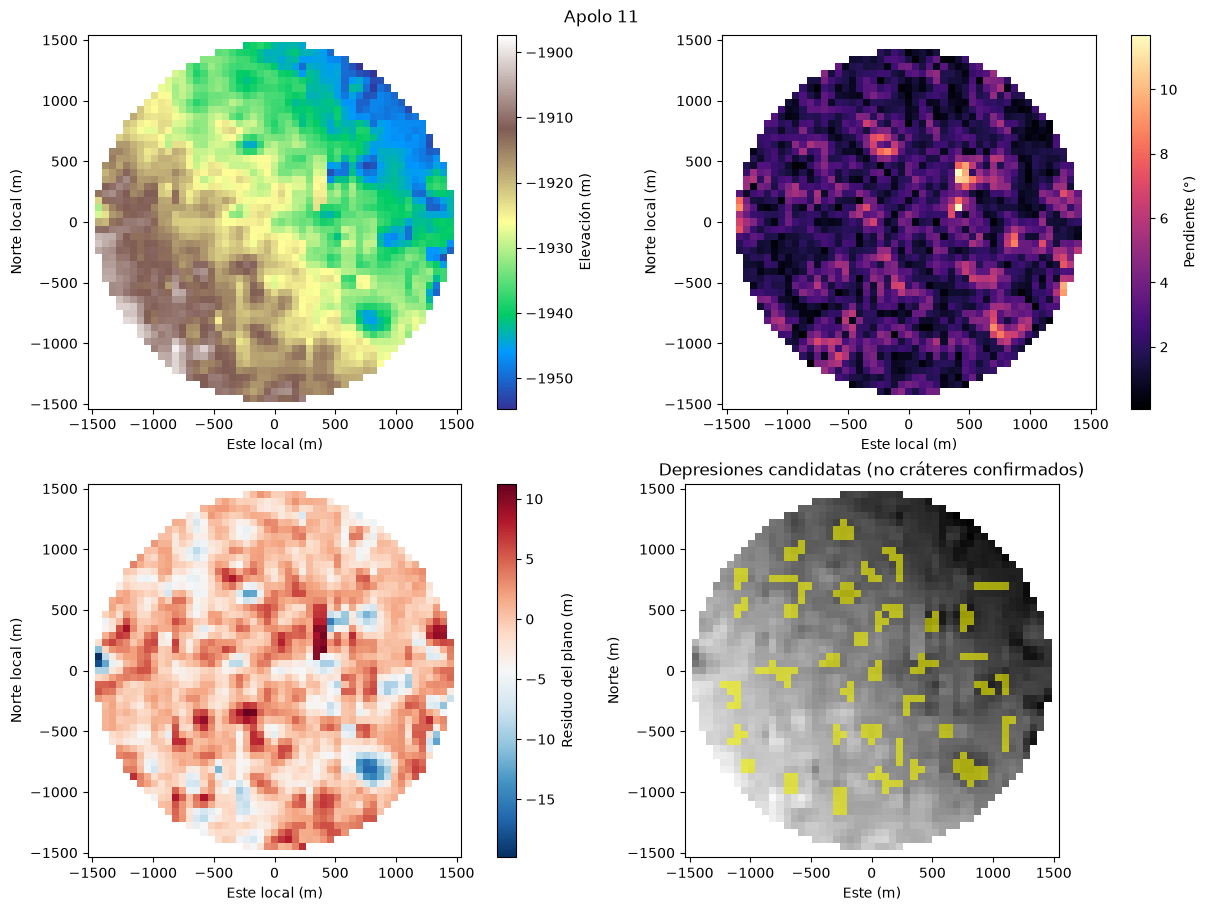

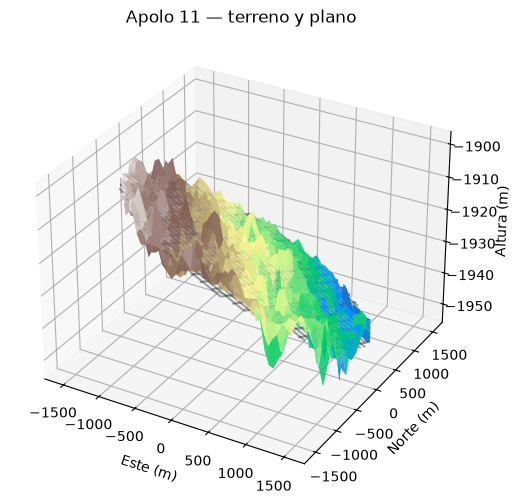

[{'radius_m': 300.0,
  'rms_m': 2.612679324411596,
  'relief_m': 14.658212661743164},
 {'radius_m': 750.0,
  'rms_m': 3.7661116855475827,
  'relief_m': 45.201659202575684},
 {'radius_m': 1500.0,
  'rms_m': 3.5810996224253064,
  'relief_m': 57.33978748321533}]

Shackleton / Site04 (5 m) — matriz NumPy (m), esquina 8x8 del rectángulo central:
[[165.07 168.38 171.63 174.8  178.02 183.83 186.43 189.03]
 [165.74 169.01 172.16 175.35 178.72 184.49 187.   189.7 ]
 [166.41 169.61 172.57 175.65 178.81 184.49 187.34 190.27]
 [166.58 169.73 172.76 175.8  178.84 184.33 187.66 190.86]
 [166.77 169.86 172.89 175.94 179.02 185.09 188.37 191.62]
 [167.02 170.01 173.   176.05 179.23 185.82 189.16 192.49]
 [167.28 170.14 173.04 176.05 179.34 186.44 189.83 193.41]
 [167.5  170.25 172.99 175.84 179.28 186.46 189.9  193.26]]


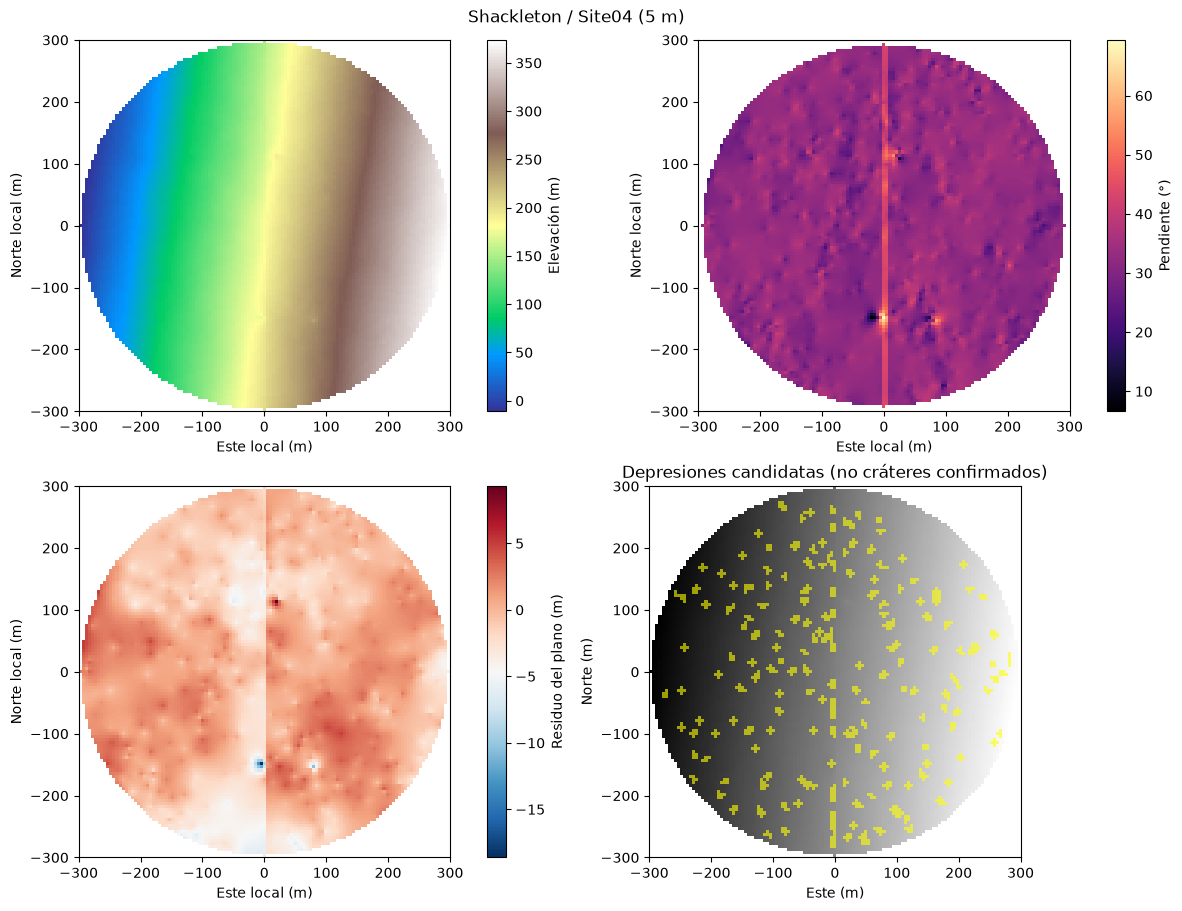

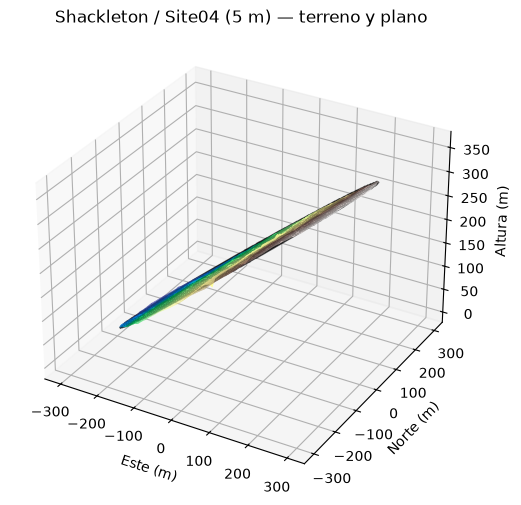

[{'radius_m': 100.0,
  'rms_m': 1.4976873373957973,
  'relief_m': 129.91970825195312},
 {'radius_m': 300.0,
  'rms_m': 1.8920034181170398,
  'relief_m': 384.78515434265137},
 {'radius_m': 750.0,
  'rms_m': 1.8920034181170398,
  'relief_m': 384.78515434265137},
 {'radius_m': 1500.0,
  'rms_m': 1.8920034181170398,
  'relief_m': 384.78515434265137}]

In [23]:
def plot_terrain(result: dict[str,Any], title: str) -> None:
    """Matriz real, pendientes, residuos, candidatos y superficie con plano ajustado."""
    dem=result['dem'];z=dem.elevation;q=result['roughness']
    print(title, '— matriz NumPy (m), esquina 8x8 del rectángulo central:')
    cy,cx=np.array(z.shape)//2
    print(np.array2string(z[cy-4:cy+4,cx-4:cx+4],precision=2))
    extent=[q['x'].min(),q['x'].max(),q['y'].min(),q['y'].max()]
    fig,axes=plt.subplots(2,2,figsize=(12,9),constrained_layout=True)
    for ax,arr,label,cmap in [(axes[0,0],z,'Elevación (m)','terrain'),
        (axes[0,1],result['slope'],'Pendiente (°)','magma'),
        (axes[1,0],q['residual'],'Residuo del plano (m)','RdBu_r')]:
        im=ax.imshow(arr,extent=extent,origin='upper',cmap=cmap)
        fig.colorbar(im,ax=ax,label=label);ax.set(xlabel='Este local (m)',ylabel='Norte local (m)')
    axes[1,1].imshow(z,extent=extent,cmap='gray')
    mask=np.ma.masked_where(~result['depressions']['depressions'],np.ones(z.shape))
    axes[1,1].imshow(mask,extent=extent,cmap='autumn',alpha=.6,vmin=0,vmax=1)
    axes[1,1].set(title='Depresiones candidatas (no cráteres confirmados)',xlabel='Este (m)',ylabel='Norte (m)')
    fig.suptitle(title);plt.show()
    fig=plt.figure(figsize=(10,6));ax=fig.add_subplot(111,projection='3d')
    stride=max(1,max(z.shape)//80)
    ax.plot_surface(q['x'][::stride,::stride],q['y'][::stride,::stride],z[::stride,::stride],cmap='terrain',alpha=.85)
    plane=np.where(np.isfinite(z),q['fitted'],np.nan)
    ax.plot_wireframe(q['x'][::stride,::stride],q['y'][::stride,::stride],plane[::stride,::stride],color='black',alpha=.35)
    ax.set(xlabel='Este (m)',ylabel='Norte (m)',zlabel='Altura (m)',title=title+' — terreno y plano')
    plt.show()
    display(result['multiscale'])

for site in ('Apolo 11','Shackleton / Site04 (5 m)'):
    if site in REMOTE_RESULTS: plot_terrain(REMOTE_RESULTS[site],site)

### 12. Comprobación independiente de Horizons y auditoría de fuentes

El encabezado se deja visible para comprobar el sitio, marco y radio. Los azimuts manuales de ejemplo no se interpretan como observaciones del aterrizaje.

In [24]:
HORIZONS_CHECK=None
if RUN_HORIZONS_CHECK:
    try:
        altitude=get_elevation(LATITUDE,LONGITUDE)+OBSERVER_HEIGHT_M
        HORIZONS_CHECK=object_directions(LATITUDE,LONGITUDE,UTC_TIME,altitude,'horizons')
        display(HORIZONS_CHECK)
        check=horizons_positions(LATITUDE,LONGITUDE,altitude,UTC_TIME,
            (parse_utc(UTC_TIME)+timedelta(minutes=1)).isoformat(),'1 min','10')
        print(check['header'])
    except Exception as exc:
        PROBLEMS.append('Horizons: '+str(exc));print('Horizons sin resultado:',exc)

for key in ('pgda67','pds'):
    try:
        links=official_links(SOURCES[key])
        print(key, 'accesible:',len(links),'enlaces oficiales')
    except Exception as exc: PROBLEMS.append(f'{key}: {exc}')

AUXILIARY_SAMPLES=[]
if RUN_REMOTE_EXPERIMENTS:
    # Audita productos oficiales de pendiente y rugosidad de bases espaciales distintas.
    for filename,unit in [('LDSM_80S_80MPP_ADJ.TIF','grados'),
                          ('LDRM_80S_1000MPP_ADJ_ROUGH_100M.TIF','m; base 100 m')]:
        try:
            url=next(u for u in official_links(SOURCES['pgda90'])
                     if urlparse(u).path.rsplit('/',1)[-1]==filename)
            meta=dataset_metadata(url)
            row,col=meta['shape'][0]//2,meta['shape'][1]//2
            arr=read_window(url,Window(col,row,8,8))
            AUXILIARY_SAMPLES.append(dict(file=filename,units=unit,shape=arr.shape,
                finite_pixels=int(np.isfinite(arr).sum()),sample=arr.tolist()))
        except Exception as exc: PROBLEMS.append(f'Producto auxiliar {filename}: {exc}')
    display(AUXILIARY_SAMPLES)

display([dict(file=urlparse(url).path.rsplit('/',1)[-1],
    cog=m['cog_layout_reported'],projection=m['projection'],native_pixel_m=m['resolution'],
    shape=m['shape'],bounds_m=m['bounds'],overviews=m['overviews'],blocks=m['blocks'],
    nodata=str(m['nodata']),gdal_scale=m['scale'],gdal_offset=m['offset'],
    frame=m['frame'],rectangular_latitude_range_deg=m['rectangular_grid_latitude_range_deg'],
    file_bytes=m['total_file_bytes']) for url,m in SOURCE_AUDIT.items()])
display([dict(file=d.name,documented_latitude_range_deg=(d.south,d.north),
    longitude_east_range_deg=(d.west,d.east),nominal_m=d.nominal_m)
    for d in build_catalog() if d.url in SOURCE_AUDIT])

{'mode': 'JPL Horizons aparente sin refracción',
 'sun': (88.805464021, 10.703170402, 0.5249288888888889),
 'earth': (272.195518253, 59.22451738, 1.8840855555555553)}

*******************************************************************************
 Revised: July 31, 2013                  Sun                                 10

 PHYSICAL PROPERTIES (updated 2024-Oct-30):
  GM, km^3/s^2          = 132712440041.93938  Mass, 10^24 kg        = ~1988410
  Vol. mean radius, km  = 695700              Volume, 10^12 km^3    = 1412000
  Solar radius (IAU2015)= 695700 km           Mean density, g/cm^3  = 1.408
  Radius (photosphere)  = 696500 km           Angular diam at 1 AU  = 1919.3"
  Photosphere temp., K  = 6600 (bottom)       Photosphere temp., K  = 4400(top)
  Photospheric depth    = ~500 km             Chromospheric depth   = ~2500 km
  Flatness, f           = 0.00005             Adopted sid. rot. per.= 25.38 d
  Surface gravity       =  274.0 m/s^2        Escape speed, km/s    =  617.7
  Pole (RA,DEC), deg.   = (286.13, 63.87)     Obliquity to ecliptic = 7.25 deg.
  Solar constant (1 AU) = 1367.6 W/m^2        Luminosity, 10^24 J/s = 382.8
  Mass-energy 

[]

[{'file': 'SLDEM2015_512_00N_30N_000_045_FLOAT.LBL',
  'cog': False,
  'projection': 'Equidistant Cylindrical (Spherical)',
  'native_pixel_m': (59.2252938, 59.2252938),
  'shape': (15360, 23040),
  'bounds_m': (-5458203.076608, 0.0, -4093652.3074560002, 909700.512768),
  'overviews': [],
  'blocks': [(1, 23040)],
  'nodata': '-3.4028226550889045e+38',
  'gdal_scale': 1.0,
  'gdal_offset': 1737.4,
  'frame': 'MOON_ME/DE421 (documentación)',
  'rectangular_latitude_range_deg': (0.0, 30.00000000143505),
  'file_bytes': 1415577600},
 {'file': 'Site04_final_adj_5mpp_surf.tif',
  'cog': False,
  'projection': 'Polar Stereographic (variant B)',
  'native_pixel_m': (5.0, 5.0),
  'shape': (3200, 3200),
  'bounds_m': (-9000.0, -15000.0, 7000.0, 1000.0),
  'overviews': [],
  'blocks': [(1, 3200)],
  'nodata': 'nan',
  'gdal_scale': 1.0,
  'gdal_offset': 0.0,
  'frame': 'MOON_ME/DE421 (documentación)',
  'rectangular_latitude_range_deg': (-90.0, -89.42312746886455),
  'file_bytes': 40980806},
 {'

[{'file': 'LDEM_80S_40MPP_ADJ.TIF',
  'documented_latitude_range_deg': (-90.0, -80.0),
  'longitude_east_range_deg': (0.0, 360.0),
  'nominal_m': 40},
 {'file': 'LDEM_83S_10MPP_ADJ.TIF',
  'documented_latitude_range_deg': (-90.0, -83.0),
  'longitude_east_range_deg': (0.0, 360.0),
  'nominal_m': 10},
 {'file': 'Site04_final_adj_5mpp_surf.tif',
  'documented_latitude_range_deg': (-90.0, -89.0),
  'longitude_east_range_deg': (0.0, 360.0),
  'nominal_m': 5.0},
 {'file': 'SLDEM2015_512_00N_30N_000_045_FLOAT.LBL',
  'documented_latitude_range_deg': (0.0, 30.0),
  'longitude_east_range_deg': (0.0, 45.0),
  'nominal_m': 59.225293797166955}]

### 13. Horizonte direccional, horizonte 360° y gráficos

La ejecución está desactivada por defecto para evitar leer automáticamente extensiones grandes.
Activa `RUN_DIRECTIONAL_HORIZON` para el Sol/Tierra y `RUN_FULL_HORIZON` para el barrido.
La distancia final se obtiene de la geometría anterior, puede superar ampliamente 100 km y
no se recorta silenciosamente. El muestreo de rayos finitos no certifica ausencia de picos.

Horizontes extensos desactivados; funciones disponibles y geometría sintética verificada.


**Demostración local limitada a 5 km:** no descarta obstáculos remotos.

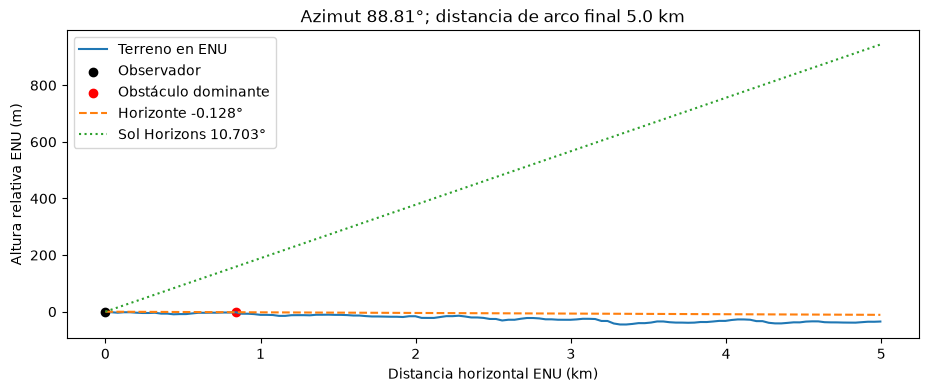

{'angle_deg': -0.1276200925886937,
 'approximate_angle_deg': -0.1274935960242704,
 'dominant': {'latitude': 0.6745774149207052,
  'longitude': 23.50069732388627,
  'distance_m': 840.0,
  'elevation_m': -1931.694507598877},
 'coverage_fraction': 1.0,
 'distance_closed': False,
 'tail_upper_bound_deg': 77.00921969335812,
 'uncertainty_deg': None,
 'notes': ['Muestreo discreto; resolución efectiva y error angular no acotados globalmente',
  'Los DEM de menor resolución pueden contener promedios: picos no garantizados',
  'El intervalo subpíxel próximo al observador no está resuelto']}

In [25]:
def plot_profile(h: dict[str,Any], object_elevation: float | None = None,
                  object_name: str = 'Objeto') -> None:
    """Perfil en ENU exacto: curvatura, observador, obstáculo y rayos de visión."""
    p=h['profile'];d=p['distances_m'];z=p['elevation_m'];t=d/R_MOON
    horizontal=(R_MOON+z)*np.sin(t)
    up=(R_MOON+z)*np.cos(t)-(R_MOON+h['observer_z_m']+h['observer_height_m'])
    fig,ax=plt.subplots(figsize=(11,4))
    ax.plot(horizontal/1000,up,label='Terreno en ENU')
    ax.scatter([0],[0],label='Observador',c='black')
    i=int(np.nanargmax(h['angles_deg']))
    ax.scatter([horizontal[i]/1000],[up[i]],label='Obstáculo dominante',c='red')
    xx=np.linspace(0,np.nanmax(horizontal),300)
    ax.plot(xx/1000,np.tan(np.radians(h['angle_deg']))*xx,'--',
            label=f"Horizonte {h['angle_deg']:.3f}°")
    if object_elevation is not None:
        ax.plot(xx/1000,np.tan(np.radians(object_elevation))*xx,':',
                label=f'{object_name} {object_elevation:.3f}°')
    ax.set(xlabel='Distancia horizontal ENU (km)',ylabel='Altura relativa ENU (m)',
           title=f"Azimut {h['azimuth_deg']:.2f}°; distancia de arco final {d[-1]/1000:.1f} km")
    ax.legend();plt.show()
    display({k:h[k] for k in ('angle_deg','approximate_angle_deg','dominant','coverage_fraction',
                              'distance_closed','tail_upper_bound_deg','uncertainty_deg','notes')})

def plot_full_horizon(h: dict[str,Any]) -> None:
    """Horizonte cartesiano/polar, comparado con esfera lisa al radio local."""
    a=np.r_[h['azimuth_deg'],360.];v=np.r_[h['angle_deg'],h['angle_deg'][0]]
    z0=get_elevation(h['latitude'],h['longitude'])
    geometric=smooth_horizon(z0,h['observer_height_m'])
    fig=plt.figure(figsize=(12,4))
    ax=fig.add_subplot(121);ax.plot(a,v,label='Topografía muestreada')
    ax.axhline(geometric,color='gray',linestyle='--',label='Esfera lisa')
    ax.set(xlabel='Azimut (°)',ylabel='Elevación (°)');ax.legend()
    polar=fig.add_subplot(122,projection='polar')
    polar.set_theta_zero_location('N');polar.set_theta_direction(-1)
    # Desplazamiento explícito evita representar radios polares negativos.
    finite=v[np.isfinite(v)];offset=max(0,1-min(finite.min() if finite.size else 0,geometric))
    polar.plot(np.radians(a),v+offset)
    polar.plot(np.radians(a),np.full(a.size,geometric+offset),'--',color='gray')
    ticks=polar.get_yticks();polar.set_yticks(ticks,labels=[f'{t-offset:.1f}°' for t in ticks])
    polar.set_title('Horizonte; etiquetas en elevación real')
    plt.show()

DIRECTIONAL_RESULTS={}
FULL_HORIZON=None
if RUN_DIRECTIONAL_HORIZON or RUN_FULL_HORIZON:
    directions=object_directions(LATITUDE,LONGITUDE,UTC_TIME,
        get_elevation(LATITUDE,LONGITUDE)+OBSERVER_HEIGHT_M)
    if RUN_DIRECTIONAL_HORIZON:
        for name in ('sun','earth'):
            az,el,diam=directions[name]
            with measure('horizon '+name):
                h=calculate_horizon_angle(LATITUDE,LONGITUDE,az,OBSERVER_HEIGHT_M)
            DIRECTIONAL_RESULTS[name]=h;plot_profile(h,el,name)
            display(_visibility(az,el,h,diam if name=='sun' else None))
    if RUN_FULL_HORIZON:
        with measure('full horizon'):
            FULL_HORIZON=calculate_full_horizon(LATITUDE,LONGITUDE,OBSERVER_HEIGHT_M,AZIMUTH_STEP_DEG)
        plot_full_horizon(FULL_HORIZON)
else: print('Horizontes extensos desactivados; funciones disponibles y geometría sintética verificada.')

LOCAL_HORIZON_DEMO=None
if RUN_LOCAL_PROFILE_DEMO:
    try:
        # Demostración pequeña del algoritmo con datos reales. No se presenta como
        # horizonte total: no cumple necesariamente el cierre geométrico de distancia.
        az,el,_=(HORIZONS_CHECK['sun'] if HORIZONS_CHECK else
                 (SOLAR_AZIMUTH_DEG,SOLAR_ELEVATION_DEG,None))
        with measure('local truncated real horizon'):
            LOCAL_HORIZON_DEMO=calculate_horizon_angle(LATITUDE,LONGITUDE,az,OBSERVER_HEIGHT_M,
                resolution_strategy=[(0.,float('inf'),80.)],max_distance_m=5000.)
        display(Markdown('**Demostración local limitada a 5 km:** no descarta obstáculos remotos.'))
        plot_profile(LOCAL_HORIZON_DEMO,el,'Sol Horizons' if HORIZONS_CHECK else 'Sol manual de ejemplo')
    except Exception as exc:
        PROBLEMS.append('Perfil real local: '+str(exc));print('Perfil local sin resultado:',exc)

### 14. Evolución temporal

Se reutiliza el mismo horizonte para todo el intervalo. Las duraciones se calculan por intervalos de retención de muestra, no contando muestras como si todas duraran un paso. El último intervalo se recorta al tiempo final; los cruces tienen incertidumbre temporal de hasta un paso. Los porcentajes son resultados del modelo muestreado sobre el tiempo conocido, con la fracción desconocida informada aparte.

In [26]:
TIME_RESULTS=None
if RUN_TIME_SERIES:
    with measure('temporal visibility'):
        TIME_RESULTS=evaluate_visibility_over_time(LATITUDE,LONGITUDE,TIME_START,TIME_END,
                                                   TIME_STEP,FULL_HORIZON)
    fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True,constrained_layout=True)
    for ax,name in zip(axes,('sun','earth')):
        r=TIME_RESULTS[name];p=r['ephemeris']
        ax.plot(p['time'],p['elevation_deg'],label=name)
        ax.plot(p['time'],[s['horizon_deg'] for s in r['samples']],label='Horizonte en azimut del objeto')
        ax.set(ylabel='Elevación (°)');ax.legend()
        display({k:v for k,v in r.items() if k not in ('ephemeris','samples','model_intervals')})
    plt.show()
else: print('Serie temporal desactivada: no hay porcentajes reales calculados para el intervalo.')

Serie temporal desactivada: no hay porcentajes reales calculados para el intervalo.


### 15. Sensibilidad espacial y geométrica

La parte pequeña compara radio y resolución de la misma región real ya leída. Para reducir
resolución se comparan la media por bloque y el máximo por bloque: un máximo preserva picos
de altura dentro del bloque pero puede sobreestimar si se asigna al centro, y no conoce su
posición exacta. **No se emplean overviews medios como una envolvente superior.**
La función remota compara altura, paso de azimut y distancia de búsqueda, conservando el
indicador de truncamiento. Su ejecución es opcional por coste de acceso. Una resolución menor
se considera suficiente sólo para la métrica y tolerancia comparadas, no para obstáculos
que quedan por debajo de su soporte espacial.

In [27]:
SENSITIVITY=[]
if 'Apolo 11' in REMOTE_RESULTS:
    original=REMOTE_RESULTS['Apolo 11'];dw=original['dem'];z=dw.elevation
    for factor in (1,2,4):
        if min(z.shape)//factor<5: continue
        nr,nc=z.shape[0]//factor,z.shape[1]//factor
        blocks=z[:nr*factor,:nc*factor].reshape(nr,factor,nc,factor)
        mean=np.mean(blocks,axis=(1,3));maximum=conservative_block_max(z,factor)
        for method,arr in [('media',mean),('máximo',maximum)]:
            s=calculate_slope(arr,dw.dx*factor,dw.dy*factor)
            q=calculate_roughness(arr,dw.dx*factor,dw.dy*factor)
            SENSITIVITY.append(dict(factor=factor,method=method,resolution_m=dw.dx*factor,
                slope_p95_deg=float(np.nanpercentile(s,95)),rms_m=q['rms_m'],
                relief_m=q['relief_m'],matrix_bytes=arr.nbytes))
    display(SENSITIVITY)
    display(original['multiscale'])

def remote_horizon_sensitivity(latitude: float, longitude: float) -> list[dict[str,Any]]:
    """Compara parámetros uno a uno; las distancias cortas quedan etiquetadas truncadas."""
    results=[]
    z0=get_elevation(latitude,longitude)
    derived=search_limit_m(z0,OBSERVER_HEIGHT_M,HORIZON_TOLERANCE_DEG)
    configs=[dict(label='base',height=OBSERVER_HEIGHT_M,step=30.,limit=None),
             dict(label='altura',height=10.,step=30.,limit=None),
             dict(label='paso angular',height=OBSERVER_HEIGHT_M,step=15.,limit=None),
             dict(label='100 km truncado',height=OBSERVER_HEIGHT_M,step=30.,limit=100000.),
             dict(label='distancia ampliada',height=OBSERVER_HEIGHT_M,step=30.,limit=derived*1.25)]
    for c in configs:
        with measure('sensitivity '+c['label']):
            h=calculate_full_horizon(latitude,longitude,c['height'],c['step'],max_distance_m=c['limit'])
        records=h['directions']
        finite=h['angle_deg'][np.isfinite(h['angle_deg'])]
        results.append(dict(configuration=c,finite_directions=int(finite.size),
            max_horizon_deg=float(np.max(finite)) if finite.size else None,
            median_horizon_deg=float(np.median(finite)) if finite.size else None,
            closed_fraction=float(np.mean([r.get('distance_closed',False) for r in records]))))
    return results

REMOTE_SENSITIVITY=remote_horizon_sensitivity(LATITUDE,LONGITUDE) if RUN_REMOTE_SENSITIVITY else None
if REMOTE_SENSITIVITY: display(REMOTE_SENSITIVITY)

LOCAL_HORIZON_SENSITIVITY=[]
if LOCAL_HORIZON_DEMO is not None:
    for height,limit,resolution in [(0.,5000.,80.),(2.,5000.,80.),(10.,5000.,80.),
                                    (2.,1000.,80.),(2.,5000.,160.)]:
        try:
            h=calculate_horizon_angle(LATITUDE,LONGITUDE,LOCAL_HORIZON_DEMO['azimuth_deg'],height,
                [(0.,float('inf'),resolution)],max_distance_m=limit)
            LOCAL_HORIZON_SENSITIVITY.append(dict(height_m=height,distance_limit_m=limit,
                requested_step_m=resolution,horizon_deg=h['angle_deg'],
                closure_satisfied=h['distance_closed'],coverage_fraction=h['coverage_fraction']))
        except Exception as exc: PROBLEMS.append('Sensibilidad local: '+str(exc))
    display(LOCAL_HORIZON_SENSITIVITY)

[{'factor': 1,
  'method': 'media',
  'resolution_m': 59.225293800002426,
  'slope_p95_deg': 5.553946677691913,
  'rms_m': 3.5810996224253064,
  'relief_m': 57.33978748321533,
  'matrix_bytes': 22472},
 {'factor': 1,
  'method': 'máximo',
  'resolution_m': 59.225293800002426,
  'slope_p95_deg': 5.553946677691913,
  'rms_m': 3.5810996224253064,
  'relief_m': 57.33978748321533,
  'matrix_bytes': 22472},
 {'factor': 2,
  'method': 'media',
  'resolution_m': 118.45058760000485,
  'slope_p95_deg': 2.8370020372644875,
  'rms_m': 3.027797456401311,
  'relief_m': 50.65631866455078,
  'matrix_bytes': 5408},
 {'factor': 2,
  'method': 'máximo',
  'resolution_m': 118.45058760000485,
  'slope_p95_deg': 2.803103882952133,
  'rms_m': 3.060657545255562,
  'relief_m': 52.448272705078125,
  'matrix_bytes': 5408},
 {'factor': 4,
  'method': 'media',
  'resolution_m': 236.9011752000097,
  'slope_p95_deg': 1.604646712515263,
  'rms_m': 2.0617423716357814,
  'relief_m': 43.10633987188339,
  'matrix_bytes':

[{'radius_m': 300.0,
  'rms_m': 2.612679324411596,
  'relief_m': 14.658212661743164},
 {'radius_m': 750.0,
  'rms_m': 3.7661116855475827,
  'relief_m': 45.201659202575684},
 {'radius_m': 1500.0,
  'rms_m': 3.5810996224253064,
  'relief_m': 57.33978748321533}]

[{'height_m': 0.0,
  'distance_limit_m': 5000.0,
  'requested_step_m': 80.0,
  'horizon_deg': 0.008950067370308389,
  'closure_satisfied': False,
  'coverage_fraction': 1.0},
 {'height_m': 2.0,
  'distance_limit_m': 5000.0,
  'requested_step_m': 80.0,
  'horizon_deg': -0.1276200925886937,
  'closure_satisfied': False,
  'coverage_fraction': 1.0},
 {'height_m': 10.0,
  'distance_limit_m': 5000.0,
  'requested_step_m': 80.0,
  'horizon_deg': -0.4904642569700697,
  'closure_satisfied': False,
  'coverage_fraction': 1.0},
 {'height_m': 2.0,
  'distance_limit_m': 1000.0,
  'requested_step_m': 80.0,
  'horizon_deg': -0.1276200925886937,
  'closure_satisfied': False,
  'coverage_fraction': 1.0},
 {'height_m': 2.0,
  'distance_limit_m': 5000.0,
  'requested_step_m': 160.0,
  'horizon_deg': -0.2086675730517386,
  'closure_satisfied': False,
  'coverage_fraction': 1.0}]

### 16. Prueba experimental del transporte parcial COG

Para medir las peticiones de **Rasterio/GDAL** se crea un proxy HTTP local de diagnóstico que
reenvía exclusivamente rangos acotados a un COG oficial. GDAL abre el COG a través de ese proxy;
se registran rangos y bytes de cuerpos recibidos para una ventana de 16×16.
El proxy rechaza GET sin `Range` y respuestas 200, por lo que no puede servir el archivo completo.
Los bytes son de cuerpo HTTP, no incluyen TLS/cabeceras; la medida se limita a este experimento.
El resto de lecturas GDAL no se atribuye incorrectamente al contador de Requests.
No se crea una API del proyecto: es una instrumentación temporal en localhost y se apaga al terminar.

In [28]:
def verify_partial_cog(dataset: Dataset) -> dict[str,Any]:
    """Mide realmente los Range de GDAL al leer una ventana remota mediante proxy local."""
    from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
    from threading import Thread
    from uuid import uuid4
    meta=dataset_metadata(dataset.url,dataset.is_pds)
    if not meta['cog_layout_reported']: raise ValueError('Se requiere COG con LAYOUT reportado')
    total=meta['total_file_bytes']; transfers=[]; failures=[]
    class Handler(BaseHTTPRequestHandler):
        def log_message(self, format: str, *args: Any) -> None: pass
        def do_HEAD(self) -> None:
            self.send_response(200);self.send_header('Content-Length',str(total))
            self.send_header('Accept-Ranges','bytes');self.send_header('Content-Type','image/tiff');self.end_headers()
        def do_GET(self) -> None:
            match=re.fullmatch(r'bytes=(\d+)-(\d+)',self.headers.get('Range',''))
            if not match: self.send_error(416,'Only bounded Range supported');return
            first,last=map(int,match.groups());last=min(last,total-1)
            try:
                data,_=read_http_range(dataset.url,first,last)
                transfers.append(dict(first=first,last=last,bytes=len(data)))
                self.send_response(206);self.send_header('Content-Length',str(len(data)))
                self.send_header('Content-Range',f'bytes {first}-{last}/{total}')
                self.send_header('Accept-Ranges','bytes');self.end_headers();self.wfile.write(data)
            except Exception as exc:
                failures.append(str(exc));self.send_error(502,str(exc))
    server=ThreadingHTTPServer(('127.0.0.1',0),Handler)
    thread=Thread(target=server.serve_forever,daemon=True);thread.start()
    try:
        url=f'http://127.0.0.1:{server.server_address[1]}/{uuid4().hex}.TIF'
        with rasterio.Env(**GDAL_OPTIONS),rasterio.open('/vsicurl/'+url) as src:
            window=Window(src.width//2,src.height//2,16,16)
            arr=src.read(1,window=window)
        sent=sum(t['bytes'] for t in transfers)
        if failures: raise RuntimeError('; '.join(failures))
        assert 0<sent<total, 'No se demostró una transferencia parcial'
        return dict(file=dataset.name,total_file_bytes=total,http_range_requests=len(transfers),
                    body_bytes_transferred=sent,fraction_transferred=sent/total,
                    output_shape=arr.shape,array_bytes=arr.nbytes,ranges=transfers)
    finally:
        server.shutdown();server.server_close();thread.join(timeout=2)

PARTIAL_ACCESS_TEST=None
if RUN_REMOTE_EXPERIMENTS:
    try:
        candidates=[d for d in build_catalog() if d.name=='LDEM_60S_240MPP_ADJ.TIF']
        if not candidates: raise RuntimeError('COG de prueba ausente en el índice oficial')
        with measure('instrumented COG range'):
            PARTIAL_ACCESS_TEST=verify_partial_cog(candidates[0])
        display(PARTIAL_ACCESS_TEST)
    except Exception as exc: PROBLEMS.append('Medición COG: '+str(exc));print('Medición no disponible:',exc)

{'file': 'LDEM_60S_240MPP_ADJ.TIF',
 'total_file_bytes': 218961039,
 'http_range_requests': 2,
 'body_bytes_transferred': 786432,
 'fraction_transferred': 0.0035916526684000617,
 'output_shape': (16, 16),
 'array_bytes': 1024,
 'ranges': [{'first': 0, 'last': 32767, 'bytes': 32768},
  {'first': 140460032, 'last': 141213695, 'bytes': 753664}]}

### 17. Resumen de resultados y limitaciones de esta ejecución

Esta celda recoge sólo resultados obtenidos. Si los experimentos opcionales no se han ejecutado, no presenta una conclusión de iluminación ni de comunicación. Un índice topográfico parcial no valida un aterrizaje.

In [29]:
SUMMARY=[]
for name,r in REMOTE_RESULTS.items():
    dw=r['dem']
    # Sólo se suman condiciones astronómicas si se han evaluado para este mismo sitio
    # con incertidumbre suficiente; no se reutilizan direcciones manuales como evidencia.
    metrics=r['metrics'].copy()
    if name=='Apolo 11' and FULL_HORIZON is not None and EPHEMERIS_MODE=='horizons':
        directions=object_directions(LATITUDE,LONGITUDE,UTC_TIME,get_elevation(LATITUDE,LONGITUDE)+OBSERVER_HEIGHT_M)
        for key in ('sun','earth'):
            az,el,diam=directions[key]
            vis=_visibility(az,el,FULL_HORIZON,diam if key=='sun' else None)
            metrics[key]=float(vis['direct_visibility']) if vis['direct_visibility'] is not None else None
    idx=viability_index(metrics)
    SUMMARY.append(dict(site=name,dataset=dw.dataset.name,pixel_m=dw.dx,
        effective_p95_m=dw.effective_resolution_m,vertical_error_p95_m=dw.vertical_rms_m,
        coverage_pct=100*dw.coverage_fraction,slope_center_deg=r['slope_statistics']['center_deg'],
        slope_mean_deg=r['slope_statistics']['mean_deg'],slope_max_deg=r['slope_statistics']['max_deg'],
        slope_p95_deg=r['slope_statistics']['p95_deg'],
        slope_exceedance_pct=r['slope_statistics']['area_above_limit_pct'],
        roughness_rms_m=r['roughness']['rms_m'],roughness_max_abs_m=r['roughness']['max_absolute_m'],
        relief_m=r['roughness']['relief_m'],plane_slope_deg=r['roughness']['plane_slope_deg'],
        candidate_regions=r['depressions']['candidate_regions'],index=idx,
        confidence=r['confidence'],warnings=dw.warnings))
display(SUMMARY)
display(dict(synthetic_tests=SYNTHETIC_TESTS,real_sites_evaluated=len(SUMMARY),
    horizons_check=HORIZONS_CHECK,full_horizon_computed=FULL_HORIZON is not None,
    local_truncated_profile_computed=LOCAL_HORIZON_DEMO is not None,
    time_series_computed=TIME_RESULTS is not None,partial_cog_access=PARTIAL_ACCESS_TEST,
    cached_window_bytes=CACHE_BYTES,explicit_http_requests=len(HTTP_LOG),
    explicit_http_body_bytes=sum(x['body_bytes'] for x in HTTP_LOG),
    all_gdal_http_requests='No instrumentado globalmente; sólo experimento proxy',
    problems=list(dict.fromkeys(PROBLEMS))))
display(PERFORMANCE)
display(Markdown('**Alcance:** resultados experimentales a la escala del DEM. '
    'No se han evaluado rocas subpíxel, propiedades mecánicas del suelo, dinámica del vehículo, '
    'antenas, Fresnel ni presupuesto de enlace. Las incertidumbres espaciales desconocidas '
    'impiden certificar visibilidad y seguridad.'))

[{'site': 'Apolo 11',
  'dataset': 'SLDEM2015_512_00N_30N_000_045_FLOAT.LBL',
  'pixel_m': 59.225293800002426,
  'effective_p95_m': None,
  'vertical_error_p95_m': None,
  'coverage_pct': 100.0,
  'slope_center_deg': 3.6536945980543547,
  'slope_mean_deg': 2.5107453502920407,
  'slope_max_deg': 11.688222160010989,
  'slope_p95_deg': 5.553946677691913,
  'slope_exceedance_pct': 0.0,
  'roughness_rms_m': 3.5810996224253064,
  'roughness_max_abs_m': 19.847545311424255,
  'relief_m': 57.33978748321533,
  'plane_slope_deg': 0.8868250696507117,
  'candidate_regions': 38,
  'index': {'partial_score_0_100': 33.28414299366296,
   'weighted_fraction_evaluated': 0.65,
   'status': 'invalidado por restricción',
   'violated': ['roughness'],
   'unknown_mandatory': [],
   'missing': ['sun', 'earth'],
   'components': {'slope': 0.5371711101923407,
    'roughness': 0.0,
    'relief': 0.4266021251678467,
    'depressions': 0.3939393939393939}},
  'confidence': {'confidence_0_100': np.float64(54.994219

{'synthetic_tests': {'plano horizontal': 'OK',
  'plano inclinado': 'OK',
  'montaña': 'OK',
  'cráter/cuenco': 'OK',
  'silla': 'OK',
  'terreno irregular': 'OK',
  'NoData': 'OK',
  'esfera sin relieve': 'OK',
  'curvatura local vs ENU': 'OK',
  'base ENU': 'OK',
  'límite geométrico': 'OK',
  '720 direcciones': 'OK',
  'máximo por bloque': 'OK',
  'disco solar': 'OK',
  'índice incompleto': 'OK',
  'restricción obligatoria': 'OK',
  'intervalos temporales': 'OK'},
 'real_sites_evaluated': 5,
 'horizons_check': {'mode': 'JPL Horizons aparente sin refracción',
  'sun': (88.805464021, 10.703170402, 0.5249288888888889),
  'earth': (272.195518253, 59.22451738, 1.8840855555555553)},
 'full_horizon_computed': False,
 'local_truncated_profile_computed': True,
 'time_series_computed': False,
 'partial_cog_access': {'file': 'LDEM_60S_240MPP_ADJ.TIF',
  'total_file_bytes': 218961039,
  'http_range_requests': 2,
  'body_bytes_transferred': 786432,
  'fraction_transferred': 0.0035916526684000617

[{'experiment': 'get_dem',
  'seconds': 3.8956199000240304,
  'shape': (53, 53),
  'matrix_bytes': 22472,
  'source_pixels': 3364,
  'output_resolution_m': 59.225293800002426,
  'effective_resolution_p95_m': None,
  'gdal_http_requests': None,
  'gdal_transfer_bytes': None},
 {'experiment': 'analyze_terrain',
  'seconds': 0.0037175000179558992,
  'shape': (53, 53),
  'matrix_bytes': 22472,
  'output_resolution_m': 59.225293800002426},
 {'experiment': 'Apolo 11',
  'seconds': 3.901517399994191,
  'python_peak_bytes': 1368915},
 {'experiment': 'get_dem',
  'seconds': 0.3755513000069186,
  'shape': (121, 121),
  'matrix_bytes': 117128,
  'source_pixels': 15876,
  'output_resolution_m': 5.0,
  'effective_resolution_p95_m': None,
  'gdal_http_requests': None,
  'gdal_transfer_bytes': None},
 {'experiment': 'analyze_terrain',
  'seconds': 0.004660999984480441,
  'shape': (121, 121),
  'matrix_bytes': 117128,
  'output_resolution_m': 5.0},
 {'experiment': 'Shackleton / Site04 (5 m)',
  'secon

**Alcance:** resultados experimentales a la escala del DEM. No se han evaluado rocas subpíxel, propiedades mecánicas del suelo, dinámica del vehículo, antenas, Fresnel ni presupuesto de enlace. Las incertidumbres espaciales desconocidas impiden certificar visibilidad y seguridad.

### Registro de la validación del 14-11-2026

Durante la creación se aprobaron los 17 grupos de pruebas sintéticas y se obtuvieron
ventanas reales de las cinco regiones. Horizons devolvió, para el sitio redondeado de
Apolo 11, azimut/elevación solar de aproximadamente 88,805°/10,703° y terrestre de
272,196°/59,225°. Estos valores son efemérides, no una demostración de visibilidad topográfica.

En una primera ejecución instrumentada, Rasterio leyó una ventana de 16×16 del COG
`LDEM_60S_240MPP_ADJ.TIF` mediante dos peticiones Range: **786 432 bytes de
218 961 039 bytes (0,36 %)**. El registro independiente está en
[`Pruebas_COG_LOLA/verificacion_acceso_parcial.json`](Pruebas_COG_LOLA/verificacion_acceso_parcial.json).
En repeticiones aparecieron errores HTTP 403 y errores de lectura en algunas fuentes PGDA;
las salidas anteriores de este cuaderno registran el resultado de la última ejecución.
El registro previo acredita una lectura parcial que sí funcionó; no sustituye una prueba
fallida posterior ni garantiza la disponibilidad futura de la fuente.

El perfil local real se limita explícitamente a 5 km y no cierra la búsqueda de obstáculos
remotos. El horizonte completo y la serie temporal larga **no se han ejecutado**.
En las pruebas adicionales de integración (`probar_adaptadores.py`), una esfera sintética
con observador a 2 m dio un horizonte de −0,08694° y cierre de distancia de unos 263,5 km
bajo la envolvente configurada. Ese caso es exclusivamente una comprobación geométrica.